# Trabajo Práctico: Predicción de Ingresos y Scoring Crediticio
* Edgardo Omar Fregosi | **Comisión:** C26241 (Lunes 19 a 21 hs)

# INTRODUCCIÓN Y CONTEXTO DE APLICACIÓN FINANCIERA

Este trabajo compara dos enfoques metodológicos para clasificar y evaluar la probabilidad de que un individuo pertenezca al estrato de ingresos altos (> $50.000 USD anuales) a partir de sus atributos sociodemográficos y laborales:

1. **Enfoque Basado en Datos (Data-Driven)**: Modelos de aprendizaje automático (Regresión de Probabilidad Lineal, Regresión Logística y Árboles de Decisión) entrenados con más de 48.000 registros del *Adult Census Income Dataset*, que capturan las interacciones empíricas y dinámicas reales del mercado laboral.
2. **Sistema Basado en Reglas Fijas (Rule-Based)**: Modelo normativo/heurístico construido sobre supuestos teóricos del capital humano (e.g., título universitario, jornada completa de 40+ horas y más de 10 años de trayectoria laboral).

### Caso de Uso de Negocio: Otorgamiento y Disposición Crediticia Preferencial
Desde la perspectiva de una entidad financiera o fintech, predecir con precisión la capacidad de ingresos permite **diseñar campañas proactivas de colocación de líneas de crédito y tarjetas de segmento premium (pre-aprobadas)**.
- Un **Falso Positivo** (ofrecer crédito a quien se presumía de altos ingresos pero no los tiene) eleva el riesgo de mora y sobreendeudamiento.
- Un **Falso Negativo** (no ofrecer crédito a quien sí califica) implica un costo de oportunidad comercial significativo frente a la competencia.

"El objetivo analítico es comparar el rendimiento de ambos paradigmas mediante K-Fold Cross-Validation. Se evaluará el desempeño clasificatorio tradicional (Matriz de Confusión, ROC-AUC, Precision, Recall y F1-Score) y, de forma complementaria, la calidad de calibración de las probabilidades predichas (utilizando métricas como el Brier Score/RMSE y
R2
  aplicado a las salidas de probabilidad). Esta doble evaluación es crucial en el ámbito crediticio, ya que permite distinguir entre un modelo que acierta 'por casualidad' y uno que genera probabilidades bien calibradas, facilitando el ajuste fino del umbral de decisión según la tolerancia al riesgo de la entidad."

# 2. INGESTA Y EXPLORACIÓN INICIAL (EDA)
## 2.1 Carga del dataset y traducción de atributos

In [ ]:
# ==============================================================================
# INGRESO DEL DATASET - Adult Census Income (KDD / OpenML)
# Fuente: U.S. Census Bureau (Extracción: Barry Becker y Ronny Kohavi, 1996)
# Repositorio oficial: OpenML / UCI Machine Learning Repository
# Descripción: Más de 48.000 registros sociodemográficos para predecir si el
#              ingreso anual de una persona supera los $50.000 USD (0: <=50K, 1: >50K).
# ==============================================================================

import pandas as pd
from sklearn.datasets import fetch_openml

# 1. Descarga y carga automática del dataset oficial
print("Cargando el dataset Adult Census Income desde OpenML...")
data = fetch_openml('adult', version=2, as_frame=True)
df = data.frame

# 2. Creación de la variable objetivo binaria (0 = <=50K, 1 = >50K)
df['target'] = (df['class'] == '>50K').astype(int)

# 3. Resumen y dimensiones de los datos
print(f"Dataset cargado exitosamente.")
print(f"Total de registros: {df.shape[0]:,}")
print(f"Total de atributos/columnas: {df.shape[1]}")

display(df)

Cargando el dataset Adult Census Income desde OpenML...
Dataset cargado exitosamente.
Total de registros: 48,842
Total de atributos/columnas: 16


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class,target
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,1
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K,0
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K,1
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K,0
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K,0


In [ ]:
# ==============================================================================
# TRADUCCIÓN Y RENOMBRADO DE COLUMNAS AL CASTELLANO
# ==============================================================================

traduccion_columnas = {
    'age': 'edad',
    'workclass': 'clase_trabajo',
    'fnlwgt': 'peso_muestral',
    'education': 'nivel_educativo',
    'education-num': 'anios_educacion',
    'marital-status': 'estado_civil',
    'occupation': 'ocupacion',
    'relationship': 'relacion_familiar',
    'race': 'raza',
    'sex': 'sexo',
    'capital-gain': 'ganancia_capital',
    'capital-loss': 'perdida_capital',
    'hours-per-week': 'horas_por_semana',
    'native-country': 'pais_origen',
    'class': 'categoria_ingreso',
    'target': 'ingreso_mayor_50k'
}

df = df.rename(columns=traduccion_columnas)

df.head()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   edad               48842 non-null  int64   
 1   clase_trabajo      46043 non-null  category
 2   peso_muestral      48842 non-null  int64   
 3   nivel_educativo    48842 non-null  category
 4   anios_educacion    48842 non-null  int64   
 5   estado_civil       48842 non-null  category
 6   ocupacion          46033 non-null  category
 7   relacion_familiar  48842 non-null  category
 8   raza               48842 non-null  category
 9   sexo               48842 non-null  category
 10  ganancia_capital   48842 non-null  int64   
 11  perdida_capital    48842 non-null  int64   
 12  horas_por_semana   48842 non-null  int64   
 13  pais_origen        47985 non-null  category
 14  categoria_ingreso  48842 non-null  category
 15  ingreso_mayor_50k  48842 non-null  int64   
dtypes: c

## 2.2 Diagnóstico preliminar de correlaciones y desbalance de clases

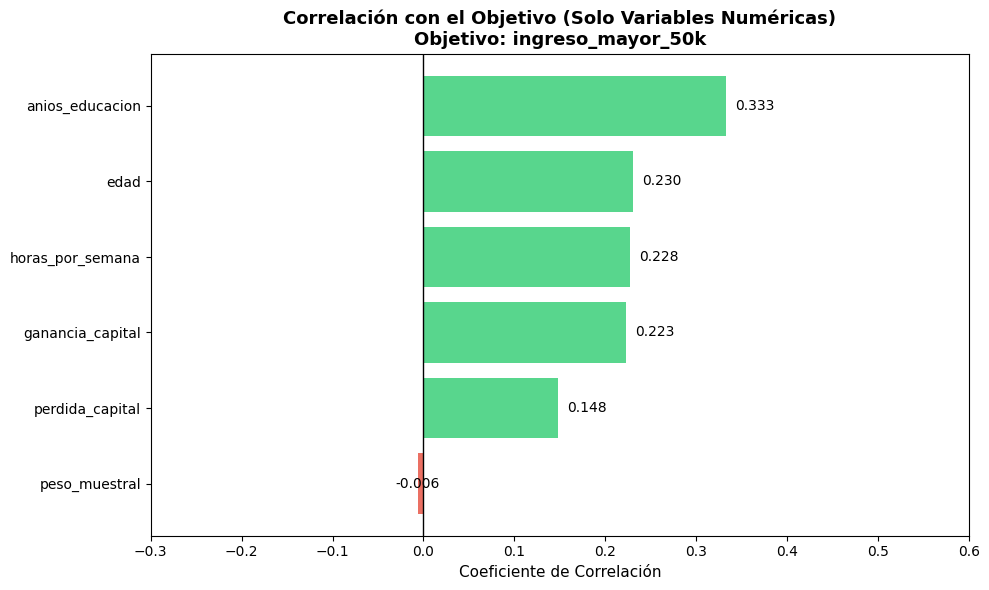


--- Correlación Numérica con 'ingreso_mayor_50k' ---
anios_educacion     0.332613
edad                0.230369
horas_por_semana    0.227687
ganancia_capital    0.223013
perdida_capital     0.147554
peso_muestral      -0.006339


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_numericas = df.select_dtypes(include=['int64', 'float64'])

corr_numericas = df_numericas.corr(method='pearson')['ingreso_mayor_50k'].drop('ingreso_mayor_50k')
corr_numericas_ordenadas = corr_numericas.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
colores = ['#2ecc71' if x >= 0 else '#e74c3c' for x in corr_numericas_ordenadas]

bars = plt.barh(corr_numericas_ordenadas.index, corr_numericas_ordenadas.values, color=colores, alpha=0.8)

for bar in bars:
    width = bar.get_width()
    plt.text(width + (0.01 if width >= 0 else -0.025),
             bar.get_y() + bar.get_height()/2,
             f'{width:.3f}', va='center', fontsize=10)

plt.axvline(0, color='black', linewidth=1)
plt.title('Correlación con el Objetivo (Solo Variables Numéricas)\nObjetivo: ingreso_mayor_50k', fontsize=13, fontweight='bold')
plt.xlabel('Coeficiente de Correlación', fontsize=11)
plt.xlim(-0.3, 0.6)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("\n--- Correlación Numérica con 'ingreso_mayor_50k' ---")
print(corr_numericas_ordenadas.to_string())

DIAGNÓSTICO DE CORRELACIÓN NUMÉRICA CON 'ingreso_mayor_50k':

1. Predictor principal: 'anios_educacion' (0.33) es la variable numérica con mayor
   poder predictivo. A mayor educación, mayor probabilidad de superar los 50K.
2. Predictores moderados: 'edad', 'horas_por_semana' y 'ganancia_capital' (~0.22-0.23)
   muestran una relación positiva consistente con el ingreso alto.
3. Variables de capital: 'perdida_capital' (0.14) también correlaciona positivamente,
   lo que sugiere que cualquier actividad de inversión (ganar o perder) está asociada
   a niveles de ingreso más altos que la inactividad financiera.
4. Ruido detectado: 'peso_muestral' (-0.006) tiene una correlación prácticamente nula.
   ACCIÓN RECOMENDADA: Eliminar esta columna antes del entrenamiento (drop), ya que
   solo aporta ruido computacional sin valor predictivo para el modelo.

📊 1. DISTRIBUCIÓN DE CLASES EN EL DATASET
Clase 0 (<=50K): 37155 personas (76.07%)
Clase 1 (>50K):  11687 personas (23.93%)
⚠️ Ratio de desbalance: 3.18:1



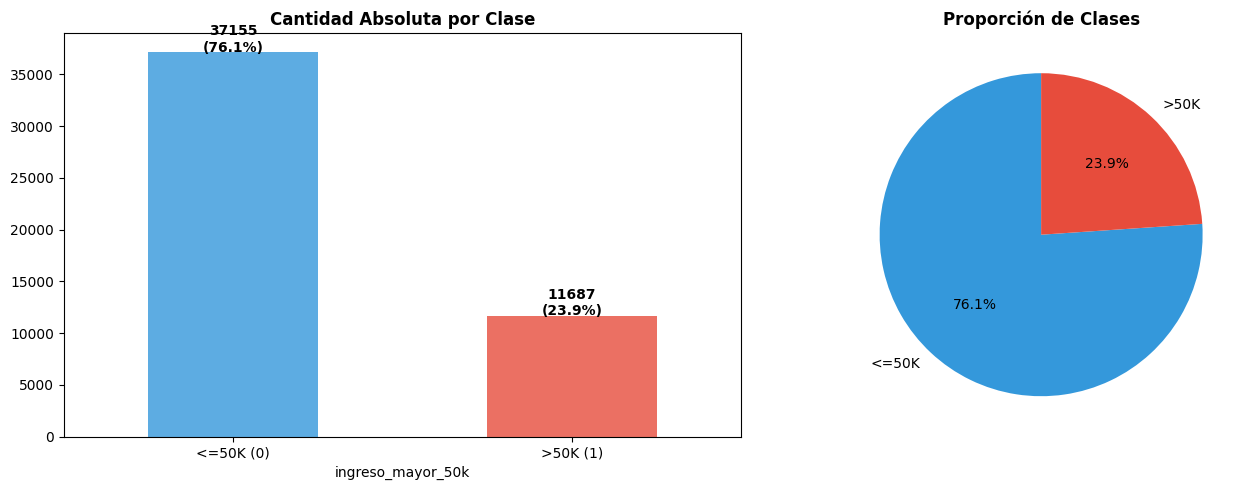

In [ ]:
# ============================================================
# PASO PREVIO: DISTRIBUCIÓN DE CLASES EN EL DATASET
# ============================================================

COL_Y = 'ingreso_mayor_50k'

if COL_Y in df.columns:
    print("="*60)
    print("📊 1. DISTRIBUCIÓN DE CLASES EN EL DATASET")
    print("="*60)

    conteo = df[COL_Y].value_counts()
    total = conteo.sum()
    ratio = conteo[0] / conteo[1]

    print(f"Clase 0 (<=50K): {conteo[0]} personas ({conteo[0]/total*100:.2f}%)")
    print(f"Clase 1 (>50K):  {conteo[1]} personas ({conteo[1]/total*100:.2f}%)")
    print(f"⚠️ Ratio de desbalance: {ratio:.2f}:1\n")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    conteo.plot(kind='bar', ax=ax1, color=['#3498db', '#e74c3c'], alpha=0.8)
    ax1.set_title('Cantidad Absoluta por Clase', fontweight='bold')
    ax1.set_xticklabels(['<=50K (0)', '>50K (1)'], rotation=0)

    for i, v in enumerate(conteo):
        ax1.text(i, v + 50, f'{v}\n({v/total*100:.1f}%)', ha='center', fontweight='bold')

    ax2.pie(conteo, labels=['<=50K', '>50K'], autopct='%1.1f%%',
            colors=['#3498db', '#e74c3c'], startangle=90)
    ax2.set_title('Proporción de Clases', fontweight='bold')

    plt.tight_layout()
    plt.show()

El dataset presenta un desbalance moderado (76.1% vs 23.9%, ratio 3.18:1). Esto implica que:

No se debe evaluar el modelo solo con Accuracy (un modelo que prediga siempre "<=50K" ya acertaría ~76%).
Se priorizarán métricas como Recall, Precision, F1-score y ROC-AUC para la clase minoritaria (>50K).
Se probará una versión de Regresión Logística con class_weight='balanced' para compensar el desbalance a nivel de entrenamiento.
Este nivel de desbalance no amerita técnicas más agresivas (oversampling/undersampling tipo SMOTE), pero queda como posible mejora futura si el recall de la clase minoritaria resulta insuficiente.

# 3. LIMPIEZA DE DATOS Y GESTIÓN DE NULOS
## 3.1 Limpieza maestra y descarte de ruido (peso_muestral / categoria_ingreso)
## 3.2 Imputación y depuración de variables categóricas críticas

In [ ]:
# ============================================================
# LIMPIEZA
# ============================================================

import pandas as pd
import numpy as np
import unicodedata
import re

PATRON_NAN_TEXTO = re.compile(r'^\s*(nan|n/?a|null|none|nd|-)\s*$', flags=re.IGNORECASE)


def normalizar_nan_texto(df):
    """Convierte cualquier variante de texto tipo NaN/N-A/null (en
    cualquier combinacion de mayusculas/minusculas) en un NaN real,
    en todas las columnas de texto antes de cualquier otra limpieza."""
    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].apply(
                lambda x: np.nan if isinstance(x, str) and PATRON_NAN_TEXTO.match(x) else x
            )
    return df


# ============================================================
# FUNCION DE ANALISIS RAPIDO
# ============================================================
def quick_analysis(df):
    print("--- 1. DIMENSIONES ---")
    print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
    print(f"Títulos de columnas: {df.columns.tolist()}")

    print("\n--- 2. DIAGNÓSTICO DE COLUMNAS ---")
    info_table = pd.DataFrame({
        'Tipo': df.dtypes,
        'Nulos': df.isnull().sum(),
        '% Nulos': (df.isnull().sum() / len(df) * 100).round(2),
        'Valores Únicos': df.nunique()
    })
    print(info_table)

    print("\n--- 3. INTEGRIDAD ---")
    print(f"Filas duplicadas totales: {df.duplicated().sum()}")

    print("\n--- 4. MUESTRA ---")
    print(df.sample(min(5, len(df))))


# ============================================================
# NORMALIZACION DE NOMBRES DE COLUMNA
# ============================================================
def limpiar_nombre_columna(col):
    """
    Normaliza el nombre de una columna:
    - saca espacios al inicio/final
    - pasa a minuscula
    - reemplaza espacios internos por guion bajo
    - saca tildes y otros diacriticos (código -> codigo)
    """
    col = str(col).strip().lower().replace(' ', '_')
    col = unicodedata.normalize('NFKD', col).encode('ascii', 'ignore').decode('utf-8')
    return col


# ============================================================
# FUNCION MAESTRA DE LIMPIEZA (igual que en limpieza.py,
# sin ningun cambio en la logica de limpieza en si)
# ============================================================
def master_clean(df):
    df.columns = [limpiar_nombre_columna(c) for c in df.columns]

    df = normalizar_nan_texto(df)

    for col in df.columns:
        if df[col].dtype == "object":
            intento = pd.to_numeric(
                df[col].astype(str).str.replace(r'[^\d.-]', '', regex=True),
                errors='coerce'
            )
            proporcion_valida = intento.notna().mean()
            if proporcion_valida >= 0.5:
                df[col] = intento

    df = df.apply(
        lambda x: x.str.strip().str.lower().str.strip('-').str.strip()
        if x.dtype == "object" else x
    )

    cols_numericas = df.select_dtypes(include=['number']).columns.tolist()
    for col in cols_numericas:
        df[col] = df[col].fillna(0)

    for col in df.columns:
        nombre_col = str(col).lower()
        if 'date' in nombre_col or 'fecha' in nombre_col:
            antes = df[col].notna().sum()
            df[col] = pd.to_datetime(df[col], errors='coerce', format='mixed')
            despues = df[col].notna().sum()

            if antes > 0 and despues == 0:
                print(f"⚠️ Columna '{col}': ningún valor pudo convertirse a fecha (revisar formato original)")
            elif despues < antes:
                perdidos = antes - despues
                print(f"⚠️ Columna '{col}': {perdidos} de {antes} valores no pudieron convertirse a fecha (quedaron NaT)")

    filas_antes = len(df)
    df = df.drop_duplicates(keep='first').reset_index(drop=True)
    filas_eliminadas = filas_antes - len(df)
    if filas_eliminadas > 0:
        print(f"🗑️ Se eliminaron {filas_eliminadas} filas totalmente duplicadas.")
    else:
        print("🗑️ No se encontraron filas totalmente duplicadas.")

    return df

df_limpio = master_clean(df.copy())
quick_analysis(df_limpio)
df_limpio.info()

display(df_limpio)

🗑️ Se eliminaron 52 filas totalmente duplicadas.
--- 1. DIMENSIONES ---
Filas: 48790 | Columnas: 16
Títulos de columnas: ['edad', 'clase_trabajo', 'peso_muestral', 'nivel_educativo', 'anios_educacion', 'estado_civil', 'ocupacion', 'relacion_familiar', 'raza', 'sexo', 'ganancia_capital', 'perdida_capital', 'horas_por_semana', 'pais_origen', 'categoria_ingreso', 'ingreso_mayor_50k']

--- 2. DIAGNÓSTICO DE COLUMNAS ---
                       Tipo  Nulos  % Nulos  Valores Únicos
edad                  int64      0     0.00              74
clase_trabajo      category   2795     5.73               8
peso_muestral         int64      0     0.00           28523
nivel_educativo    category      0     0.00              16
anios_educacion       int64      0     0.00              16
estado_civil       category      0     0.00               7
ocupacion          category   2805     5.75              14
relacion_familiar  category      0     0.00               6
raza               category      0     0

,edad,clase_trabajo,peso_muestral,nivel_educativo,anios_educacion,estado_civil,ocupacion,relacion_familiar,raza,sexo,ganancia_capital,perdida_capital,horas_por_semana,pais_origen,categoria_ingreso,ingreso_mayor_50k
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,0
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,0
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,1
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,1
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48785,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K,0
48786,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K,1
48787,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K,0
48788,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K,0


Tratamiento de variables -- Primera etapa basada en post código Limpieza Maestra

In [ ]:
#==============================================================================
# TRATAMIENTO DE VARIABLES -- PRIMERA ETAPA DE LIMPIEZA
# ==============================================================================

# Eliminación de columnas por: Data Leakage, Ruido y Ética Normativa (Fair Lending)
COLS_EXCLUIR = [
    'categoria_ingreso',  # Target original en texto: se excluye para evitar Data Leakage
    'peso_muestral',      # Peso muestral: no es una variable predictiva real, aporta ruido
    'raza',               # Ética/Normativa: Variable protegida. No debe usarse para scoring crediticio.
    'sexo'                # Ética/Normativa: Variable protegida. No debe usarse para scoring crediticio.
]

df_limpio = df_limpio.drop(columns=[c for c in COLS_EXCLUIR if c in df_limpio.columns])
print(f"🗑️ Columnas excluidas por ruido, leakage o normativa ética: {COLS_EXCLUIR}")


# ============================================================
# TRATAMIENTO DE NULOS EN CATEGORICAS (clase_trabajo, ocupacion)
# ============================================================
# A diferencia de las columnas numericas (que ya fueron
# imputadas/completadas en el script de limpieza general),
# estas columnas categoricas conservaron sus NaN originales
# porque el paso de limpieza previo solo actua sobre dtypes
# numericos. Para no perder esas filas ni imputar con la moda
# (lo que sesgaria la columna hacia la categoria mas frecuente),
# se agrega una etiqueta explicita "Sin_dato" con el fin de
# diferenciar previo eliminación
# ============================================================
for col in ['clase_trabajo', 'ocupacion']:
    nulos_antes = df_limpio[col].isnull().sum()
    if 'Sin_dato' not in df_limpio[col].cat.categories:
        df_limpio[col] = df_limpio[col].cat.add_categories('Sin_dato')
    df_limpio[col] = df_limpio[col].fillna('Sin_dato')
    if nulos_antes > 0:
        print(f"🏷️ Columna '{col}': {nulos_antes} valores NaN reemplazados por la etiqueta 'Sin_dato'.")

# Eliminar registros con "Sin_dato" en columnas específicas,
# debido a la baja insidensia en registros
columnas = ['clase_trabajo', 'ocupacion']

df_limpio = df_limpio[
    ~df_limpio[columnas].eq("Sin_dato").any(axis=1)
].copy()
df_limpio = df_limpio.reset_index(drop=True)

print("Filas restantes:", len(df_limpio))

print(df_limpio['clase_trabajo'].value_counts(dropna=False))
print()
print(df_limpio['ocupacion'].value_counts(dropna=False))

df_limpio.info()

🗑️ Columnas excluidas por ruido, leakage o normativa ética: ['categoria_ingreso', 'peso_muestral', 'raza', 'sexo']
🏷️ Columna 'clase_trabajo': 2795 valores NaN reemplazados por la etiqueta 'Sin_dato'.
🏷️ Columna 'ocupacion': 2805 valores NaN reemplazados por la etiqueta 'Sin_dato'.
Filas restantes: 45985
clase_trabajo
Private             33860
Self-emp-not-inc     3861
Local-gov            3136
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked            0
Sin_dato                0
Name: count, dtype: int64

ocupacion
Prof-specialty       6165
Craft-repair         6102
Exec-managerial      6082
Adm-clerical         5606
Sales                5501
Other-service        4919
Machine-op-inspct    3017
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1485
Tech-support         1445
Protective-serv       982
Priv-house-serv       240
Armed-Forces           15
Sin_dato                0
Name: count, dtype:

In [ ]:
df_limpio['pais_origen'].value_counts(normalize=True, dropna=False).head(10)

,proportion
pais_origen,
United-States,0.897162
Mexico,0.019463
NaN,0.017614
Philippines,0.006132
Germany,0.004197
Puerto-Rico,0.003806
Canada,0.003545
India,0.003197
El-Salvador,0.003197


In [ ]:
# pais_origen tiene 89.76% concentrado en "United-States" (verificado con
# value_counts), con las 40 categorias restantes repartiendose el resto
# en proporciones muy chicas (Mexico 1.93% siendo la segunda mas alta).
# Por esa concentracion, se agrupa en 3 categorias en vez de mantener las
# 41 originales, para no inflar el dataset con columnas dummy casi vacias
# tras el One-Hot Encoding
df_limpio['pais_origen'] = df_limpio['pais_origen'].cat.add_categories('Sin_dato').fillna('Sin_dato')

df_limpio['pais_origen'] = df_limpio['pais_origen'].apply(
    lambda x: x if x in ['Sin_dato', 'United-States'] else 'Otro'
).astype('category')

print(df_limpio['pais_origen'].value_counts(normalize=True))

pais_origen
United-States    0.897162
Otro             0.085223
Sin_dato         0.017614
Name: proportion, dtype: float64


In [ ]:
# Eliminar filas donde pais_origen es "Sin_dato" , por ser Nan poca incidensia

df_limpio = df_limpio[~df_limpio['pais_origen'].isin(['Sin_dato'])]

# Limpiar categorías no usadas
df_limpio['pais_origen'] = df_limpio['pais_origen'].cat.remove_unused_categories()

# Verificación
print(df_limpio['pais_origen'].value_counts(normalize=True))
print(f"Filas restantes: {len(df_limpio)}")

# Eliminamos columna fantasma
df_limpio['ocupacion'] = df_limpio['ocupacion'].cat.remove_unused_categories()

df_limpio.info()

pais_origen
United-States    0.913248
Otro             0.086752
Name: proportion, dtype: float64
Filas restantes: 45175
<class 'pandas.core.frame.DataFrame'>
Index: 45175 entries, 0 to 45984
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   edad               45175 non-null  int64   
 1   clase_trabajo      45175 non-null  category
 2   nivel_educativo    45175 non-null  category
 3   anios_educacion    45175 non-null  int64   
 4   estado_civil       45175 non-null  category
 5   ocupacion          45175 non-null  category
 6   relacion_familiar  45175 non-null  category
 7   ganancia_capital   45175 non-null  int64   
 8   perdida_capital    45175 non-null  int64   
 9   horas_por_semana   45175 non-null  int64   
 10  pais_origen        45175 non-null  category
 11  ingreso_mayor_50k  45175 non-null  int64   
dtypes: category(6), int64(6)
memory usage: 2.7 MB


# 4. TRANSFORMACIONES Y TRATAMIENTO DE VARIABLES
## 4.1 Diagnóstico de valores atípicos (Criterio IQR)
## 4.2 Matriz de correlación y análisis Spearman
## 4.3 Reducción de redundancia (Eliminación de nivel_educativo)
## 4.4 One-Hot Encoding y depuración de dummies
## 4.5 Gráfico de correlación final de predictoras

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COL_Y = 'ingreso_mayor_50k'   # por las dudas, si no quedo definida de antes

CARPETA_SALIDAS = "salidas"
os.makedirs(CARPETA_SALIDAS, exist_ok=True)

UMBRAL_CARDINALIDAD_CATEGORICA = 50   # texto con mas categorias que esto -> se descarta (probable ID)
UMBRAL_CORR_EJE = 0.02                # |correlacion| menor a esto = "pegada al eje", candidata a descarte
MULTIPLICADOR_IQR = 1.5

Sección 2 — Detección automática de columnas

In [ ]:
cols_candidatas = [c for c in df_limpio.columns if c != COL_Y]

cols_fecha = []
cols_numericas = []
cols_categoricas = []
cols_descartadas = []

for col in cols_candidatas:
    serie = df_limpio[col]

    if pd.api.types.is_numeric_dtype(serie):
        cols_numericas.append(col)
        continue

    if pd.api.types.is_datetime64_any_dtype(serie):
        cols_fecha.append(col)
        continue

    intento_fecha = pd.to_datetime(serie, errors="coerce", format="mixed")
    proporcion_valida = intento_fecha.notna().mean()

    if proporcion_valida > 0.9:
        cols_fecha.append(col)
        continue

    n_unicos = serie.nunique(dropna=True)

    if n_unicos <= UMBRAL_CARDINALIDAD_CATEGORICA:
        cols_categoricas.append(col)
    else:
        cols_descartadas.append(col)

print("Columnas de FECHA detectadas:      ", cols_fecha)
print("Columnas NUMERICAS detectadas:     ", cols_numericas)
print("Columnas CATEGORICAS detectadas:   ", cols_categoricas)
print("Columnas DESCARTADAS (alta cardinalidad, probable ID):", cols_descartadas)

Columnas de FECHA detectadas:       []
Columnas NUMERICAS detectadas:      ['edad', 'anios_educacion', 'ganancia_capital', 'perdida_capital', 'horas_por_semana']
Columnas CATEGORICAS detectadas:    ['clase_trabajo', 'nivel_educativo', 'estado_civil', 'ocupacion', 'relacion_familiar', 'pais_origen']
Columnas DESCARTADAS (alta cardinalidad, probable ID): []


Sección 3 — Diagnóstico de atípicos (boxplots)

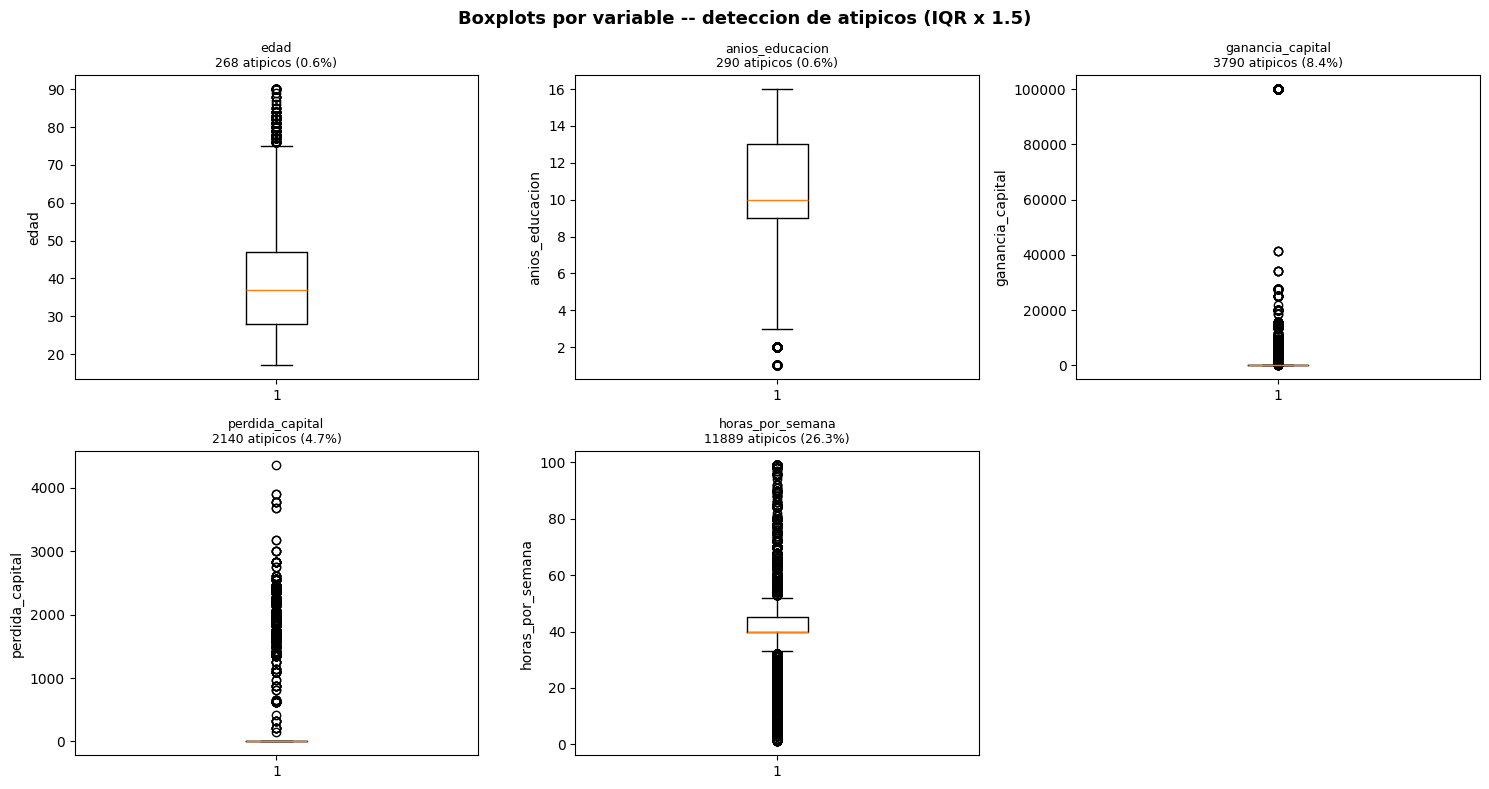


--- Resumen de valores atipicos por variable (metodo IQR) ---
        Variable   Q1   Q3  IQR  Limite_inf  Limite_sup  Cantidad_atipicos  Porcentaje_atipicos
horas_por_semana 40.0 45.0  5.0        32.5        52.5              11889                26.32
ganancia_capital  0.0  0.0  0.0         0.0         0.0               3790                 8.39
 perdida_capital  0.0  0.0  0.0         0.0         0.0               2140                 4.74
 anios_educacion  9.0 13.0  4.0         3.0        19.0                290                 0.64
            edad 28.0 47.0 19.0        -0.5        75.5                268                 0.59


In [ ]:
cols_atipicos = [c for c in cols_numericas if df_limpio[c].nunique(dropna=True) > 2]

resumen_atipicos = []

if cols_atipicos:
    n_cols_grid = 3
    n_filas_grid = -(-len(cols_atipicos) // n_cols_grid)
    fig, axes = plt.subplots(n_filas_grid, n_cols_grid, figsize=(5 * n_cols_grid, 4 * n_filas_grid))
    axes = axes.flatten() if len(cols_atipicos) > 1 else [axes]

    for i, col in enumerate(cols_atipicos):
        q1 = df_limpio[col].quantile(0.25)
        q3 = df_limpio[col].quantile(0.75)
        iqr = q3 - q1
        limite_inf = q1 - MULTIPLICADOR_IQR * iqr
        limite_sup = q3 + MULTIPLICADOR_IQR * iqr

        cantidad = int(((df_limpio[col] < limite_inf) | (df_limpio[col] > limite_sup)).sum())
        porcentaje = cantidad / len(df_limpio) * 100

        resumen_atipicos.append({
            "Variable": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
            "Limite_inf": round(limite_inf, 2), "Limite_sup": round(limite_sup, 2),
            "Cantidad_atipicos": cantidad, "Porcentaje_atipicos": round(porcentaje, 2),
        })

        axes[i].boxplot(df_limpio[col].dropna())
        axes[i].set_title(f"{col}\n{cantidad} atipicos ({porcentaje:.1f}%)", fontsize=9)
        axes[i].set_ylabel(col)

    for j in range(len(cols_atipicos), len(axes)):
        axes[j].axis("off")

    plt.suptitle(f"Boxplots por variable -- deteccion de atipicos (IQR x {MULTIPLICADOR_IQR})",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "boxplots_atipicos.png"), dpi=150)
    plt.show()

    print("\n--- Resumen de valores atipicos por variable (metodo IQR) ---")
    print(pd.DataFrame(resumen_atipicos).sort_values("Cantidad_atipicos", ascending=False).to_string(index=False))
else:
    print("No se detectaron variables numericas continuas para analizar atipicos.")

"Chequeo de valores fuera de rango lógico en variables numéricas y eliminación de registros inválidos"

In [ ]:
# Función reutilizable de chequeo de rango plausible
def chequear_rango(df, columna, minimo, maximo):
    mascara = (df[columna] < minimo) | (df[columna] > maximo)
    cantidad = mascara.sum()
    print(f"{columna} fuera de rango [{minimo}, {maximo}]: {cantidad}")
    if cantidad > 0:
        display(df[mascara])
    return mascara

# Lista de columnas a chequear: (nombre_columna, minimo, maximo)
rangos_a_chequear = [
    ("edad", 17, 90),
    ("anios_educacion", 1, 16),
    ("horas_por_semana", 1, 99),
]

# Un solo bloque que chequea y elimina para todas las columnas de la lista
for columna, minimo, maximo in rangos_a_chequear:
    mascara = chequear_rango(df_limpio, columna, minimo, maximo)
    if mascara.sum() > 0:
        df_limpio = df_limpio[~mascara].reset_index(drop=True)
        print(f"Se eliminaron {mascara.sum()} registros fuera de rango de {columna}.\n")
    else:
        print(f"Sin registros fuera de rango en {columna}.\n")

edad fuera de rango [17, 90]: 0
Sin registros fuera de rango en edad.

anios_educacion fuera de rango [1, 16]: 0
Sin registros fuera de rango en anios_educacion.

horas_por_semana fuera de rango [1, 99]: 0
Sin registros fuera de rango en horas_por_semana.



"Análisis bivariado: horas_por_semana vs. ingreso_mayor_50k (discretización y tabulación cruzada)"

In [ ]:
pd.crosstab(
    pd.cut(
        df_limpio["horas_por_semana"],
        bins=[0, 20, 30, 40, 50, 60, 80, 100]
    ),
    df_limpio["ingreso_mayor_50k"],
    normalize="index"
)

ingreso_mayor_50k,0,1
horas_por_semana,,
"(0, 20]",0.936300,0.063700
"(20, 30]",0.931423,0.068577
"(30, 40]",0.790796,0.209204
"(40, 50]",0.601821,0.398179
"(50, 60]",0.564110,0.435890
"(60, 80]",0.626450,0.373550
"(80, 100]",0.668919,0.331081


Del bloque anterior se extrae :Estos registros no deben eliminarse: son datos reales y válidos, no errores de carga. El hallazgo de no linealidad es información a documentar y a tener en cuenta al elegir el algoritmo de modelado (favoreciendo modelos no lineales como el Árbol de Decisión), no un criterio de exclusión de registros — eliminar datos porque contradicen la hipótesis inicial constituye un sesgo metodológico (cherry-picking), no una limpieza de datos válida."

In [ ]:
# ============================================================
# GANANCIA DE CAPITAL vs INGRESO MAYOR A 50K
# ============================================================

df_limpio["ganancia_capital"] \
    .gt(0) \
    .groupby(df_limpio["ingreso_mayor_50k"]) \
    .mean()

,ganancia_capital
ingreso_mayor_50k,
0,0.041651
1,0.212016


"a diferencia del análisis de horas_por_semana (que agrupa por franjas de la predictora), este bloque agrupa directamente por el target y calcula, dentro de cada clase, la proporción de casos donde la predictora binaria (ganancia_capital > 0) es verdadera — apropiado cuando la variable de interés ya es binaria o se binariza, y no requiere discretización en franjas."

"Análisis bivariado (crosstab): probabilidad de ingreso alto según presencia de ganancia de capital"

In [ ]:
tabla_ganancia = pd.crosstab(
    df_limpio["ganancia_capital"].gt(0),
    df_limpio["ingreso_mayor_50k"],
    normalize="index"
)

tabla_ganancia.index = [
    "Sin ganancia de capital (0)",
    "Con ganancia de capital (>0)"
]

tabla_ganancia

ingreso_mayor_50k,0,1
Sin ganancia de capital (0),0.786710,0.213290
Con ganancia de capital (>0),0.373351,0.626649


"Análisis bivariado (crosstab): probabilidad de ingreso alto según presencia de pérdida de capital"

In [ ]:
tabla_perdida = pd.crosstab(
    df_limpio["perdida_capital"].gt(0),
    df_limpio["ingreso_mayor_50k"],
    normalize="index"
)

tabla_perdida.index = [
    "Sin pérdida de capital (0)",
    "Con pérdida de capital (>0)"
]

tabla_perdida

ingreso_mayor_50k,0,1
Sin pérdida de capital (0),0.765214,0.234786
Con pérdida de capital (>0),0.486916,0.513084


"Se detectaron valores atípicos mediante el método IQR. Sin embargo, no seran eliminados automáticamente debido a que se encuentran dentro de rangos plausibles para las variables analizadas y presentan información potencialmente relevante para la predicción de ingreso_mayor_50k. En particular, las variables horas_por_semana, ganancia_capital y perdida_capital mostraron diferencias en la distribución del objetivo según sus valores."
Decisión adoptada

A partir de este análisis, no se eliminaran registros utilizando el criterio IQR.

Los valores detectados como atípicos estadísticos se conservarán porque:

Se encuentran dentro de rangos plausibles.
No se identificaron como valores imposibles o errores evidentes.
Algunas de estas observaciones presentan información relevante para predecir ingreso_mayor_50k.
La eliminación automática de estos registros podría reducir considerablemente el tamaño del conjunto de datos y eliminar información útil para el modelo.
La decisión tomada en esta etapa es específicamente no eliminar observaciones por el solo hecho de haber sido clasificadas como outliers mediante IQR.

Sección 4 — Tratamiento de atípicos (winsorizing)

In [ ]:
MODO_TRATAMIENTO = "ninguno"   # "ninguno" | "winsorizing" | "eliminar_filas"

if cols_atipicos and MODO_TRATAMIENTO == "winsorizing":
    for fila in resumen_atipicos:
        col = fila["Variable"]
        df_limpio[col] = df_limpio[col].clip(lower=fila["Limite_inf"], upper=fila["Limite_sup"])
    print("Listo. Valores atipicos recortados (winsorizing). No se elimino ninguna fila.")

elif cols_atipicos and MODO_TRATAMIENTO == "eliminar_filas":
    filas_antes = len(df_limpio)
    mascara = pd.Series(False, index=df_limpio.index)
    for fila in resumen_atipicos:
        col = fila["Variable"]
        mascara |= (df_limpio[col] < fila["Limite_inf"]) | (df_limpio[col] > fila["Limite_sup"])
    df_limpio = df_limpio[~mascara].reset_index(drop=True)
    print(f"Filas eliminadas por atipicos: {filas_antes - len(df_limpio)} de {filas_antes}")

else:
    print("No se aplico ningun tratamiento de atipicos (modo 'ninguno').")

No se aplico ningun tratamiento de atipicos (modo 'ninguno').


Sección 5 — Matriz de correlación

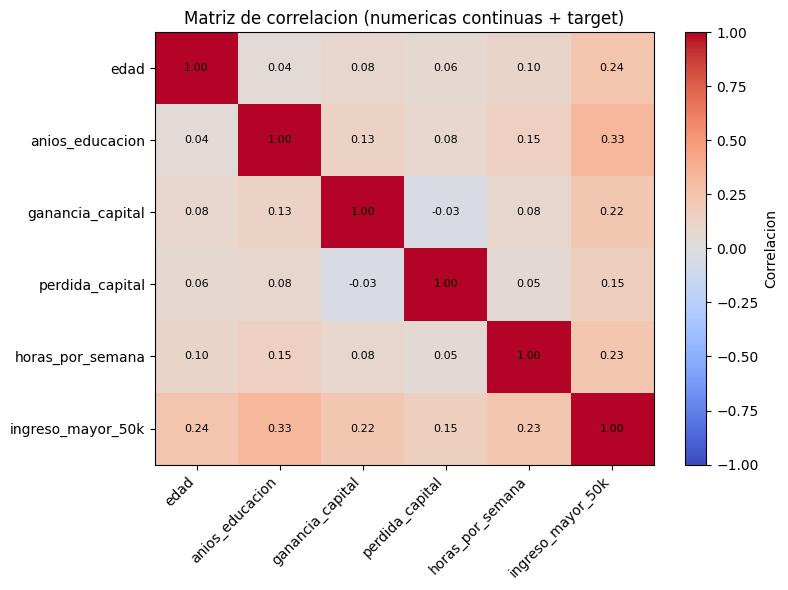

In [ ]:
cols_numericas_reales = [c for c in cols_numericas if df_limpio[c].nunique(dropna=True) > 2]

cols_para_corr = cols_numericas_reales + [COL_Y]
matriz_corr = df_limpio[cols_para_corr].corr()

plt.figure(figsize=(8, 6))
plt.imshow(matriz_corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlacion")
plt.xticks(range(len(matriz_corr.columns)), matriz_corr.columns, rotation=45, ha="right")
plt.yticks(range(len(matriz_corr.columns)), matriz_corr.columns)
for i in range(len(matriz_corr.columns)):
    for j in range(len(matriz_corr.columns)):
        plt.text(j, i, f"{matriz_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Matriz de correlacion (numericas continuas + target)")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_SALIDAS, "matriz_correlacion.png"), dpi=150)
plt.show()

"En una matriz de correlación aplicada a un problema predictivo, hay dos lecturas con criterios opuestos: (1) entre predictoras, se busca correlación BAJA (evita multicolinealidad y mantiene estable al modelo); (2) entre cada predictora y el target, una correlación baja-moderada NO invalida la variable — es esperable en fenómenos multicausales como el ingreso, y no implica ausencia de poder predictivo, ya que Pearson no detecta relaciones no lineales (como el caso demostrado con horas_por_semana) ni el aporte que una variable puede tener en combinación con otras dentro de un modelo multivariado."

Sección 6 — Correlación Spearman BRUTA (antes del One-Hot) — 2 gráficos


--- [BRUTO - NUMERICAS] Correlacion Spearman con 'ingreso_mayor_50k' (5 variables) ---
En zona de ruido (|corr| < 0.02): []


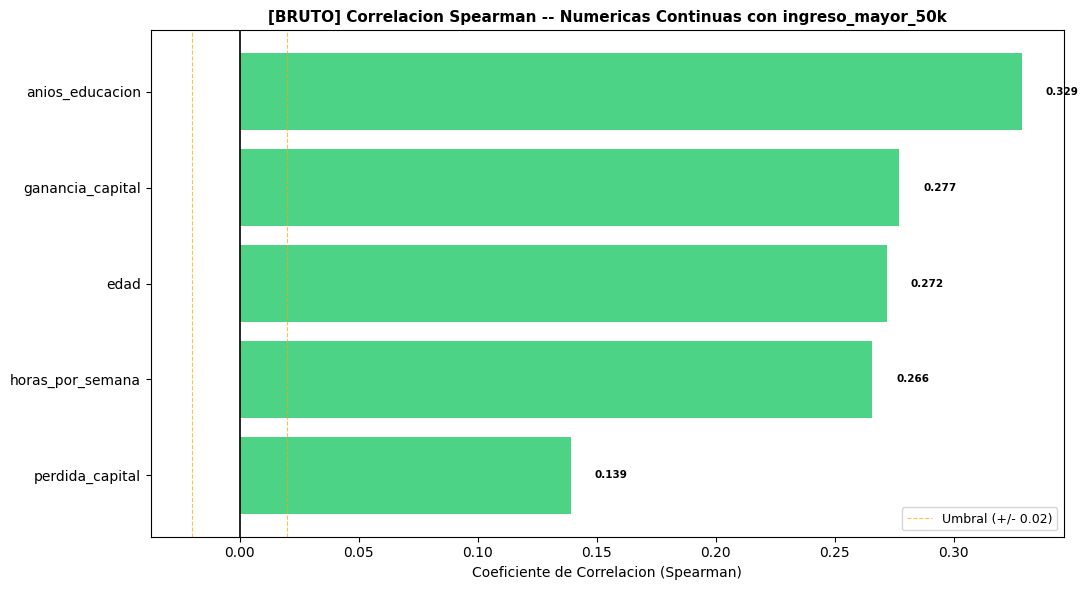

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]



--- [BRUTO - CATEGORICAS] Correlacion Spearman con 'ingreso_mayor_50k' (48 variables) ---
En zona de ruido (|corr| < 0.02): ['ocupacion_Sales', 'ocupacion_Tech-support', 'estado_civil_Married-AF-spouse', 'clase_trabajo_State-gov', 'nivel_educativo_Assoc-acdm', 'nivel_educativo_Assoc-voc', 'ocupacion_Armed-Forces', 'clase_trabajo_Without-pay']


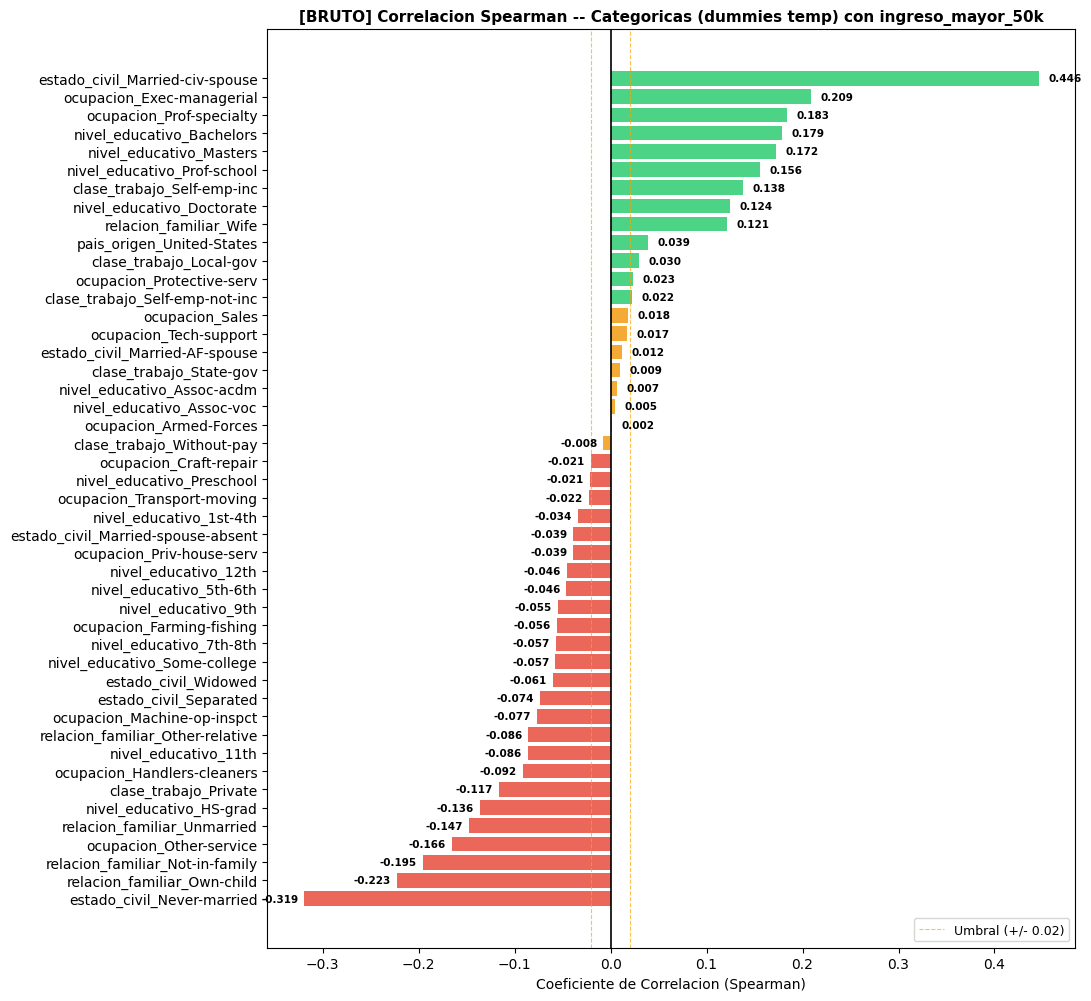

In [ ]:
cols_sugeridas_eje_bruto_num = []
cols_sugeridas_eje_bruto_cat = []

# --- (A) NUMERICAS ---
cols_a_evaluar_num = [c for c in cols_numericas_reales if c != COL_Y]

if cols_a_evaluar_num:
    corr_num = df_limpio[cols_a_evaluar_num].apply(lambda col: col.corr(df_limpio[COL_Y], method='spearman')).dropna()
    corr_num_ordenadas = corr_num.sort_values(ascending=False)
    cols_sugeridas_eje_bruto_num = corr_num_ordenadas[corr_num_ordenadas.abs() < UMBRAL_CORR_EJE].index.tolist()

    print(f"\n--- [BRUTO - NUMERICAS] Correlacion Spearman con '{COL_Y}' ({len(cols_a_evaluar_num)} variables) ---")
    print(f"En zona de ruido (|corr| < {UMBRAL_CORR_EJE}): {cols_sugeridas_eje_bruto_num}")

    altura = max(6, len(corr_num_ordenadas) * 0.22)
    plt.figure(figsize=(11, altura))
    colores = ['#f39c12' if abs(x) < UMBRAL_CORR_EJE else ('#2ecc71' if x >= 0 else '#e74c3c')
               for x in corr_num_ordenadas]
    bars = plt.barh(corr_num_ordenadas.index, corr_num_ordenadas.values, color=colores, alpha=0.85)
    for bar in bars:
        width = bar.get_width()
        plt.text(width + (0.01 if width >= 0 else -0.045), bar.get_y() + bar.get_height() / 2,
                  f'{width:.3f}', va='center', fontsize=7.5, fontweight='bold')
    plt.axvline(0, color='black', linewidth=1.2)
    plt.axvline(UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7, label=f"Umbral (+/- {UMBRAL_CORR_EJE})")
    plt.axvline(-UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7)
    plt.title(f"[BRUTO] Correlacion Spearman -- Numericas Continuas con {COL_Y}", fontsize=11, fontweight='bold')
    plt.xlabel('Coeficiente de Correlacion (Spearman)')
    plt.legend(loc='lower right', fontsize=9)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "correlacion_bruto_numericas.png"), dpi=150)
    plt.show()
else:
    print("\n[BRUTO - NUMERICAS] No hay numericas reales para evaluar.")

# --- (B) CATEGORICAS (via dummies temporales) ---
if cols_categoricas:
    df_dummies_temp = pd.get_dummies(df_limpio[cols_categoricas + [COL_Y]], columns=cols_categoricas, drop_first=True)
    cols_dummies_temp = [c for c in df_dummies_temp.columns if c != COL_Y]

    corr_cat = df_dummies_temp[cols_dummies_temp].apply(lambda col: col.corr(df_dummies_temp[COL_Y], method='spearman')).dropna()
    corr_cat_ordenadas = corr_cat.sort_values(ascending=False)
    cols_sugeridas_eje_bruto_cat = corr_cat_ordenadas[corr_cat_ordenadas.abs() < UMBRAL_CORR_EJE].index.tolist()

    print(f"\n--- [BRUTO - CATEGORICAS] Correlacion Spearman con '{COL_Y}' ({len(cols_dummies_temp)} variables) ---")
    print(f"En zona de ruido (|corr| < {UMBRAL_CORR_EJE}): {cols_sugeridas_eje_bruto_cat}")

    altura = max(6, len(corr_cat_ordenadas) * 0.22)
    plt.figure(figsize=(11, altura))
    colores = ['#f39c12' if abs(x) < UMBRAL_CORR_EJE else ('#2ecc71' if x >= 0 else '#e74c3c')
               for x in corr_cat_ordenadas]
    bars = plt.barh(corr_cat_ordenadas.index, corr_cat_ordenadas.values, color=colores, alpha=0.85)
    for bar in bars:
        width = bar.get_width()
        plt.text(width + (0.01 if width >= 0 else -0.045), bar.get_y() + bar.get_height() / 2,
                  f'{width:.3f}', va='center', fontsize=7.5, fontweight='bold')
    plt.axvline(0, color='black', linewidth=1.2)
    plt.axvline(UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7, label=f"Umbral (+/- {UMBRAL_CORR_EJE})")
    plt.axvline(-UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7)
    plt.title(f"[BRUTO] Correlacion Spearman -- Categoricas (dummies temp) con {COL_Y}", fontsize=11, fontweight='bold')
    plt.xlabel('Coeficiente de Correlacion (Spearman)')
    plt.legend(loc='lower right', fontsize=9)
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "correlacion_bruto_categoricas.png"), dpi=150)
    plt.show()

    del df_dummies_temp
else:
    print("\n[BRUTO - CATEGORICAS] No hay categoricas detectadas para evaluar.")

Sección 7— Filtro de columnas redundantes

In [ ]:
# ==============================================================================
# PASO  — ELIMINAR COLUMNAS ORIGINALES REDUNDANTES (ANTES DEL ONE-HOT)
# ==============================================================================
# 'nivel_educativo' es 1 a 1 idéntica a 'anios_educacion'. La eliminamos entera
# para no generar 12-16 dummies innecesarias que luego tendríamos que borrar.
COLS_ORIGINALES_ELIMINAR = [
    'nivel_educativo'
]

df_limpio = df_limpio.drop(columns=[c for c in COLS_ORIGINALES_ELIMINAR if c in df_limpio.columns])

# Actualizamos la lista de categóricas para que no intente procesar las eliminadas
cols_categoricas = [c for c in cols_categoricas if c not in COLS_ORIGINALES_ELIMINAR]

print(" Columnas originales eliminadas:", COLS_ORIGINALES_ELIMINAR)

 Columnas originales eliminadas: ['nivel_educativo']


In [ ]:
cols_ruido = ['ocupacion_Armed-Forces', 'estado_civil_Married-AF-spouse',
              'clase_trabajo_Without-pay']   # ajustá según  decisión
ELIMINAR_RUIDO = True      #False   True para aplicar

if ELIMINAR_RUIDO:
    df_limpio = df_limpio.drop(columns=cols_ruido, errors="ignore")

In [ ]:
print(df_limpio.shape)
print([c for c in cols_ruido if c in df_limpio.columns])   # debería dar []

(45175, 11)
[]


✅ Dummies generadas: 33
🗑️ Eliminadas 12 dummies de baja frecuencia/importancia:
   ['ocupacion_Armed-Forces', 'estado_civil_Married-AF-spouse', 'clase_trabajo_Without-pay', 'ocupacion_Machine-op-inspct', 'ocupacion_Handlers-cleaners', 'ocupacion_Priv-house-serv', 'clase_trabajo_Self-emp-inc', 'clase_trabajo_Local-gov', 'relacion_familiar_Other-relative', 'estado_civil_Separated', 'estado_civil_Widowed', 'estado_civil_Married-spouse-absent']
📊 Total columnas restantes en df_limpio: 27

--- Correlación Spearman Dummies con 'ingreso_mayor_50k' (21 variables) ---
Total en zona de advertencia / ruido (|corr| < 0.02): 3
  -> ['ocupacion_Sales', 'ocupacion_Tech-support', 'clase_trabajo_State-gov']


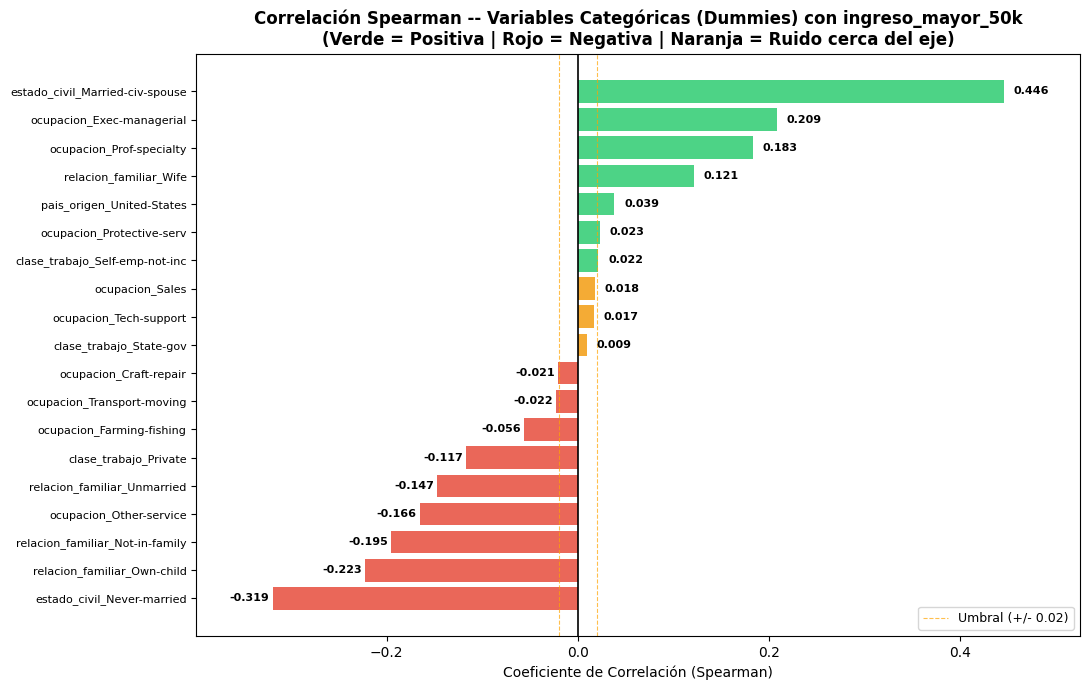

✅ Dummies eliminadas manualmente aún presentes: []
   (Debería ser [] si la eliminación fue exitosa)

️ Dummies en zona de ruido (|corr| < 0.02) que AÚN están en el dataset: 3
   - clase_trabajo_State-gov: correlación = 0.0095
   - ocupacion_Sales: correlación = 0.0181
   - ocupacion_Tech-support: correlación = 0.0174

💡 Estas NO se eliminaron porque no están en COLS_DUMMIES_ELIMINAR
   Eliminarlas sería overkill y podría remover información marginalmente útil.

 Total columnas en df_limpio: 27


In [ ]:
import warnings
from scipy.stats import ConstantInputWarning

# Silenciar warnings molestos de scipy y pandas
warnings.filterwarnings('ignore', category=ConstantInputWarning)
warnings.filterwarnings('ignore', message='.*SettingWithCopy.*')
warnings.filterwarnings('ignore', category=DeprecationWarning)
# ==============================================================================
# PASO – ONE-HOT ENCODING DEFINITIVO
# ==============================================================================
if cols_categoricas:
    df_limpio = pd.get_dummies(
        df_limpio,
        columns=cols_categoricas,
        prefix=cols_categoricas,
        dtype=int,
        drop_first=True
    )
    # Detectamos automáticamente las dummies creadas
    cols_dummies_generadas = [
        c for c in df_limpio.columns
        if any(c.startswith(cat + "_") for cat in cols_categoricas)
    ]
    print(f"✅ Dummies generadas: {len(cols_dummies_generadas)}")
else:
    cols_dummies_generadas = []

# ==============================================================================
# PASO – FILTRAR DUMMIES ESPECÍFICAS DE BAJA IMPORTANCIA/FRECUENCIA
# ==============================================================================
# Se eliminan categorías que presentan:
# 1. Muy baja frecuencia (<50 observaciones, ~0.1% del dataset)
# 2. Baja importancia predictiva (<0.5% feature importance en RandomForest)
# Esto reduce dimensionalidad sin pérdida significativa de información.
# ==============================================================================

COLS_DUMMIES_ELIMINAR = [
    # =========================================================
    # CATEGORÍAS DE MUY BAJA FRECUENCIA (<50 observaciones)
    # =========================================================
    'ocupacion_Armed-Forces',           # Personal militar (~9 casos)
    'estado_civil_Married-AF-spouse',   # Cónyuge de militar (~15 casos)
    'clase_trabajo_Without-pay',        # Sin pago (~5 casos)

    # =========================================================
    # CATEGORÍAS DE BAJA IMPORTANCIA PREDICTIVA
    # =========================================================
    'ocupacion_Machine-op-inspct',
    'ocupacion_Handlers-cleaners',
    'ocupacion_Priv-house-serv',
    'clase_trabajo_Self-emp-inc',
    'clase_trabajo_Local-gov',
    'relacion_familiar_Other-relative',
    'estado_civil_Separated',
    'estado_civil_Widowed',
    'estado_civil_Married-spouse-absent'
]

# Filtrado seguro (solo elimina si existen en el DataFrame)
a_borrar_presentes = [c for c in COLS_DUMMIES_ELIMINAR if c in df_limpio.columns]

if a_borrar_presentes:
    df_limpio = df_limpio.drop(columns=a_borrar_presentes)
    print(f"🗑️ Eliminadas {len(a_borrar_presentes)} dummies de baja frecuencia/importancia:")
    print(f"   {a_borrar_presentes}")
else:
    print("ℹ️ No se requirió eliminar ninguna dummy adicional.")


print(f"📊 Total columnas restantes en df_limpio: {df_limpio.shape[1]}")


# ==============================================================================
# GRÁFICO DE CORRELACIÓN SPEARMAN: Definitivo antes del testeo
# ==============================================================================
import os
import matplotlib.pyplot as plt
import pandas as pd

COL_Y = 'ingreso_mayor_50k'
UMBRAL_CORR_EJE = 0.02
CARPETA_SALIDAS = "salidas"
os.makedirs(CARPETA_SALIDAS, exist_ok=True)

# 1. Variables continuas conocidas para excluirlas y quedarnos SOLO con las dummies
cols_continuas = ['edad', 'anios_educacion', 'horas_por_semana', 'ganancia_capital', 'perdida_capital']

# Detectamos todas las columnas dummies reales presentes en df_limpio
cols_a_evaluar_dummies = [
    c for c in df_limpio.columns
    if c != COL_Y and c not in cols_continuas
]

if cols_a_evaluar_dummies and COL_Y in df_limpio.columns:
    # 2. Cálculo de correlación Spearman de cada dummy con el target
    corr_dum = df_limpio[cols_a_evaluar_dummies].apply(
        lambda col: col.corr(df_limpio[COL_Y], method='spearman')
    ).dropna()

    corr_dum_ordenadas = corr_dum.sort_values(ascending=False)
    dummies_en_ruido = corr_dum_ordenadas[corr_dum_ordenadas.abs() < UMBRAL_CORR_EJE].index.tolist()

    print(f"\n--- Correlación Spearman Dummies con '{COL_Y}' ({len(cols_a_evaluar_dummies)} variables) ---")
    print(f"Total en zona de advertencia / ruido (|corr| < {UMBRAL_CORR_EJE}): {len(dummies_en_ruido)}")
    if dummies_en_ruido:
        print(f"  -> {dummies_en_ruido}")

    # 3. Gráfico grande horizontal
    altura_grafico = max(7, len(corr_dum_ordenadas) * 0.25)
    plt.figure(figsize=(11, altura_grafico))

    colores = [
        '#f39c12' if abs(x) < UMBRAL_CORR_EJE else ('#2ecc71' if x >= 0 else '#e74c3c')
        for x in corr_dum_ordenadas
    ]

    bars = plt.barh(corr_dum_ordenadas.index, corr_dum_ordenadas.values, color=colores, alpha=0.85)

    # Etiquetas de valor en cada barra
    for bar in bars:
        width = bar.get_width()
        desplazamiento = 0.01 if width >= 0 else -0.045
        plt.text(
            width + desplazamiento,
            bar.get_y() + bar.get_height() / 2,
            f'{width:.3f}',
            va='center',
            fontsize=8,
            fontweight='bold'
        )

    plt.axvline(0, color='black', linewidth=1.2)
    plt.axvline(UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7, label=f"Umbral (+/- {UMBRAL_CORR_EJE})")
    plt.axvline(-UMBRAL_CORR_EJE, color='orange', linestyle='--', linewidth=0.8, alpha=0.7)

    plt.title(
        f"Correlación Spearman -- Variables Categóricas (Dummies) con {COL_Y}\n"
        f"(Verde = Positiva | Rojo = Negativa | Naranja = Ruido cerca del eje)",
        fontsize=12,
        fontweight='bold'
    )
    plt.xlabel('Coeficiente de Correlación (Spearman)', fontsize=10)
    plt.legend(loc='lower right', fontsize=9)
    plt.yticks(fontsize=8)

    # Ajuste de márgenes horizontales para que no se corten los textos
    min_x = min(corr_dum_ordenadas.min(), -UMBRAL_CORR_EJE) - 0.08
    max_x = max(corr_dum_ordenadas.max(), UMBRAL_CORR_EJE) + 0.08
    plt.xlim(min_x, max_x)

    plt.gca().invert_yaxis()

    # ✅ CORRECCIÓN APLICADA: Sin el guión al final
    plt.tight_layout()

    plt.savefig(os.path.join(CARPETA_SALIDAS, "correlacion_dummies_final.png"), dpi=150)
    plt.show()

else:
    print("No se encontraron columnas dummies o no existe el target en df_limpio.")

# ==============================================================================
# VERIFICACIÓN FINAL COMPLETA
# ==============================================================================

# 1. Verificar que las dummies eliminadas manualmente ya no están
eliminadas_manualmente = [c for c in COLS_DUMMIES_ELIMINAR if c in df_limpio.columns]
print(f"✅ Dummies eliminadas manualmente aún presentes: {eliminadas_manualmente}")
print(f"   (Debería ser [] si la eliminación fue exitosa)")

# 2. Identificar dummies que siguen en zona de ruido (|corr| < 0.02) pero NO se eliminaron
cols_continuas = ['edad', 'anios_educacion', 'horas_por_semana', 'ganancia_capital', 'perdida_capital']
dummies_restantes = [c for c in df_limpio.columns if c != COL_Y and c not in cols_continuas]

if dummies_restantes:
    corr_restantes = df_limpio[dummies_restantes].apply(
        lambda col: col.corr(df_limpio[COL_Y], method='spearman')
    ).dropna()

    en_ruido_no_eliminadas = corr_restantes[corr_restantes.abs() < UMBRAL_CORR_EJE].index.tolist()

    print(f"\n️ Dummies en zona de ruido (|corr| < {UMBRAL_CORR_EJE}) que AÚN están en el dataset: {len(en_ruido_no_eliminadas)}")
    if en_ruido_no_eliminadas:
        for col in en_ruido_no_eliminadas:
            print(f"   - {col}: correlación = {corr_restantes[col]:.4f}")
        print(f"\n💡 Estas NO se eliminaron porque no están en COLS_DUMMIES_ELIMINAR")
        print(f"   Eliminarlas sería overkill y podría remover información marginalmente útil.")
else:
    print("\nℹ️ No hay dummies restantes para evaluar")

print(f"\n Total columnas en df_limpio: {df_limpio.shape[1]}")

# 5. PARTICIÓN DE DATOS Y ESTANDARIZACIÓN
## 5.1 Split Train / Test estratificado (75% / 25%)
## 5.2 Escalado StandardScaler (sin Data Leakage)
## 5.3 Exportación del dataset procesado (df_limpio.csv)

In [ ]:
## ==============================================================================
# 5. PARTICIÓN DE DATOS Y ESTANDARIZACIÓN
# ==============================================================================
import joblib
from google.colab import files
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

TEST_SIZE = 0.25
RANDOM_STATE = 42

# 1. Definición explícita de las 5 variables numéricas continuas
cols_numericas_reales = [
    'edad',
    'anios_educacion',
    'horas_por_semana',
    'ganancia_capital',
    'perdida_capital',
]

# Forzar tipo numérico float64 en df_limpio
for col in cols_numericas_reales:
    if col in df_limpio.columns:
        df_limpio[col] = (
            pd.to_numeric(df_limpio[col], errors='coerce').fillna(0).astype(float)
        )

# 2. Identificar variables dummies y lista completa de predictoras
cols_dummies = [
    c
    for c in df_limpio.columns
    if c not in cols_numericas_reales and c != COL_Y
]
predictoras = [c for c in cols_numericas_reales if c in df_limpio.columns] + [
    c for c in cols_dummies if c in df_limpio.columns
]

print(f'Total predictoras: {len(predictoras)}')
print('Dummies eliminadas presentes en predictoras:',
      [c for c in cols_ruido if c in predictoras])

# ==============================================================================
# GUARDAR COPIA CRUDA PARA EL SISTEMA DE REGLAS (Valores reales en años/horas)
# ==============================================================================
df_limpio_raw = df_limpio.copy()

# ==============================================================================
# 3. SPLIT TRAIN / TEST
# ==============================================================================
X = df_limpio[predictoras].copy()
y = df_limpio[COL_Y].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

# Partición cruda para el Sistema de Reglas Heurístico
X_raw = df_limpio_raw[predictoras].copy()
X_train_raw, X_test_raw, _, _ = train_test_split(
    X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f'\nTrain: {len(X_train):,} filas | Test: {len(X_test):,} filas')

# ==============================================================================
# 4. ESTANDARIZAR
# ==============================================================================
scaler = StandardScaler()
X_train[cols_numericas_reales] = scaler.fit_transform(X_train[cols_numericas_reales])
X_test[cols_numericas_reales] = scaler.transform(X_test[cols_numericas_reales])

# Guardar el scaler entrenado
joblib.dump(scaler, 'scaler.pkl')

print('\nComprobación: numéricas de TRAIN estandarizadas (media 0, desvío 1):')
print(X_train[cols_numericas_reales].describe().round(3))

print('\nComprobación: numéricas de TEST (media y desvío tomados de train, no exactamente 0/1):')
print(X_test[cols_numericas_reales].describe().round(3))

# ==============================================================================
# 5. EXPORTACIÓN Y DESCARGA DEL CSV (PREENTREGA)
# ==============================================================================
# Exportamos X_train ya escalado, con el target de vuelta, para tener un
# archivo de referencia (train procesado)
df_train_export = X_train.copy()
df_train_export[COL_Y] = y_train.values
df_train_export.to_csv('df_train_procesado.csv', index=False, encoding='utf-8')
files.download('df_train_procesado.csv')

Total predictoras: 26
Dummies eliminadas presentes en predictoras: []

Train: 33,881 filas | Test: 11,294 filas

Comprobación: numéricas de TRAIN estandarizadas (media 0, desvío 1):
            edad  anios_educacion  horas_por_semana  ganancia_capital  \
count  33881.000        33881.000         33881.000         33881.000   
mean      -0.000            0.000             0.000             0.000   
std        1.000            1.000             1.000             1.000   
min       -1.633           -3.578            -3.319            -0.147   
25%       -0.799           -0.443            -0.081            -0.147   
50%       -0.116           -0.051            -0.081            -0.147   
75%        0.643            1.125             0.335            -0.147   
max        3.907            2.300             4.819            12.951   

       perdida_capital  
count        33881.000  
mean             0.000  
std              1.000  
min             -0.221  
25%             -0.221  
50%       

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ==============================================================================
# VERIFICACIÓN FINAL DE INTEGRIDAD DE DATOS
# ==============================================================================
print("\n" + "="*60)
print("VERIFICACIÓN FINAL ANTES DEL MODELADO")
print("="*60)

# 1. Verificar que las columnas éticamente sensibles NO estén
cols_prohibidas = ['raza', 'sexo', 'categoria_ingreso', 'peso_muestral']
cols_presentes_prohibidas = [c for c in cols_prohibidas if c in df_limpio.columns]
if not cols_presentes_prohibidas:
    print("✅ Ética: Variables protegidas ('raza', 'sexo') y de leakage NO están en el dataset.")
else:
    print(f"⚠️ ALERTA: Estas columnas aún están presentes: {cols_presentes_prohibidas}")

# 2. Verificar dummies eliminadas
eliminadas_manualmente = [c for c in COLS_DUMMIES_ELIMINAR if c in df_limpio.columns]
print(f"✅ Dummies de baja frecuencia eliminadas correctamente: {len(eliminadas_manualmente) == 0}")

# 3. Resumen de features finales
cols_continuas = ['edad', 'anios_educacion', 'horas_por_semana', 'ganancia_capital', 'perdida_capital']
dummies_finales = [c for c in df_limpio.columns if c != COL_Y and c not in cols_continuas]
print(f"📊 Resumen final: {len(cols_continuas)} variables continuas + {len(dummies_finales)} dummies = {df_limpio.shape[1]-1} predictoras totales.")
print("="*60)


VERIFICACIÓN FINAL ANTES DEL MODELADO
✅ Ética: Variables protegidas ('raza', 'sexo') y de leakage NO están en el dataset.
✅ Dummies de baja frecuencia eliminadas correctamente: True
📊 Resumen final: 5 variables continuas + 21 dummies = 26 predictoras totales.


#MODELADO Y EVALUACIÓN COMPARATIVA

=== BÚSQUEDA DE K PARA KNN (F1 promedio en 5-Fold CV sobre train) ===


,K,F1 promedio (CV)
0,3,0.637398
1,5,0.647833
2,7,0.652048
3,9,0.654499
4,11,0.654958
5,15,0.657150
6,21,0.656936



Mejor K encontrado: 15
Modelos actuales en la comparación: ['Regresión Logística', 'Regresión Logística (Balanced)', 'Árbol de Decisión', 'Modelo Prob. Lineal (LPM)', 'KNN (k=15)']
=== RESULTADOS CROSS-VALIDATION (5 Folds - Train) ===


,ROC-AUC (CV),F1-Score (CV),Precision (CV),Recall (CV)
Modelo,,,,
Regresión Logística,0.9027,0.6611,0.7345,0.6011
Regresión Logística (Balanced),0.9028,0.6825,0.5759,0.8375
Árbol de Decisión,0.8923,0.6410,0.7766,0.5462
Modelo Prob. Lineal (LPM),0.8907,0.6119,0.7371,0.5233
KNN (k=15),0.8920,0.6571,0.7068,0.6142



=== COMPARACIÓN FINAL EN TEST (DATA-DRIVEN VS. REGLAS) ===


,Accuracy,Balanced Acc,Recall,Specificity,Precision,F1-Score,ROC-AUC,PR-AUC,RMSE,MAE,R2
Modelo,,,,,,,,,,,
Regresión Logística,0.8474,0.7604,0.5876,0.9331,0.7435,0.6564,0.9041,0.7659,0.3242,0.2100,0.4364
Regresión Logística (Balanced),0.8069,0.8169,0.8368,0.7970,0.5762,0.6825,0.9037,0.7630,0.3583,0.2497,0.3116
Árbol de Decisión,0.8535,0.7462,0.5334,0.9590,0.8111,0.6435,0.8923,0.7300,0.3240,0.2094,0.4372
Modelo Prob. Lineal (LPM),0.8355,0.7261,0.5091,0.9431,0.7470,0.6055,0.8881,0.7292,0.3428,0.2565,0.3699
KNN (k=15),0.8403,0.7603,0.6016,0.9190,0.7101,0.6513,0.8887,0.7279,0.3322,0.2084,0.4084
Sistema Basado en Reglas,0.7861,0.6684,0.4348,0.9019,0.5939,0.5021,0.6684,0.3984,0.4625,0.2139,-0.1470


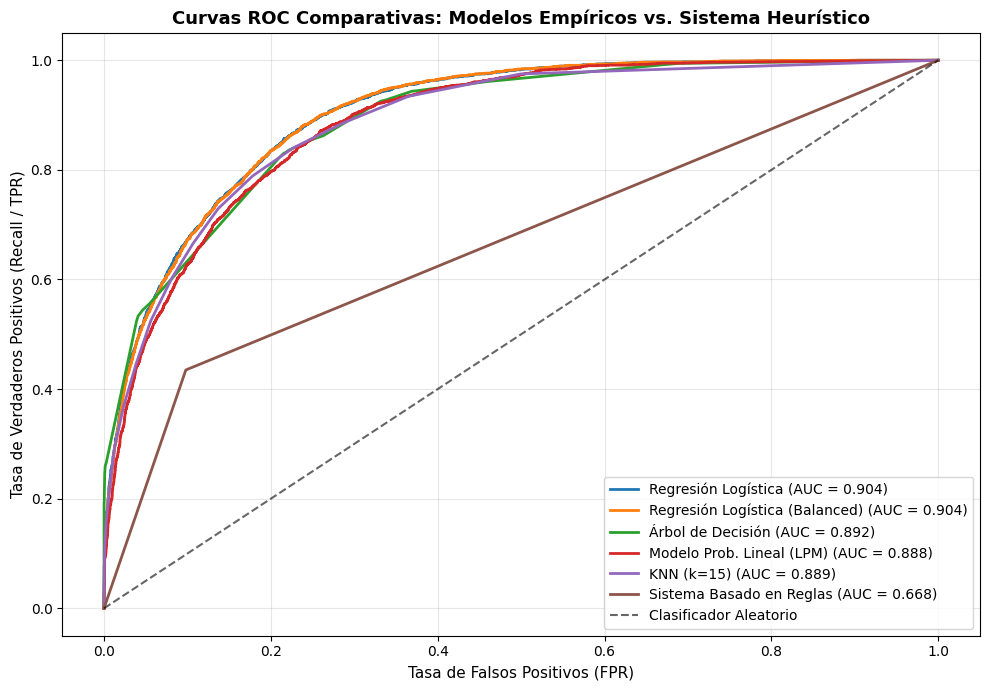

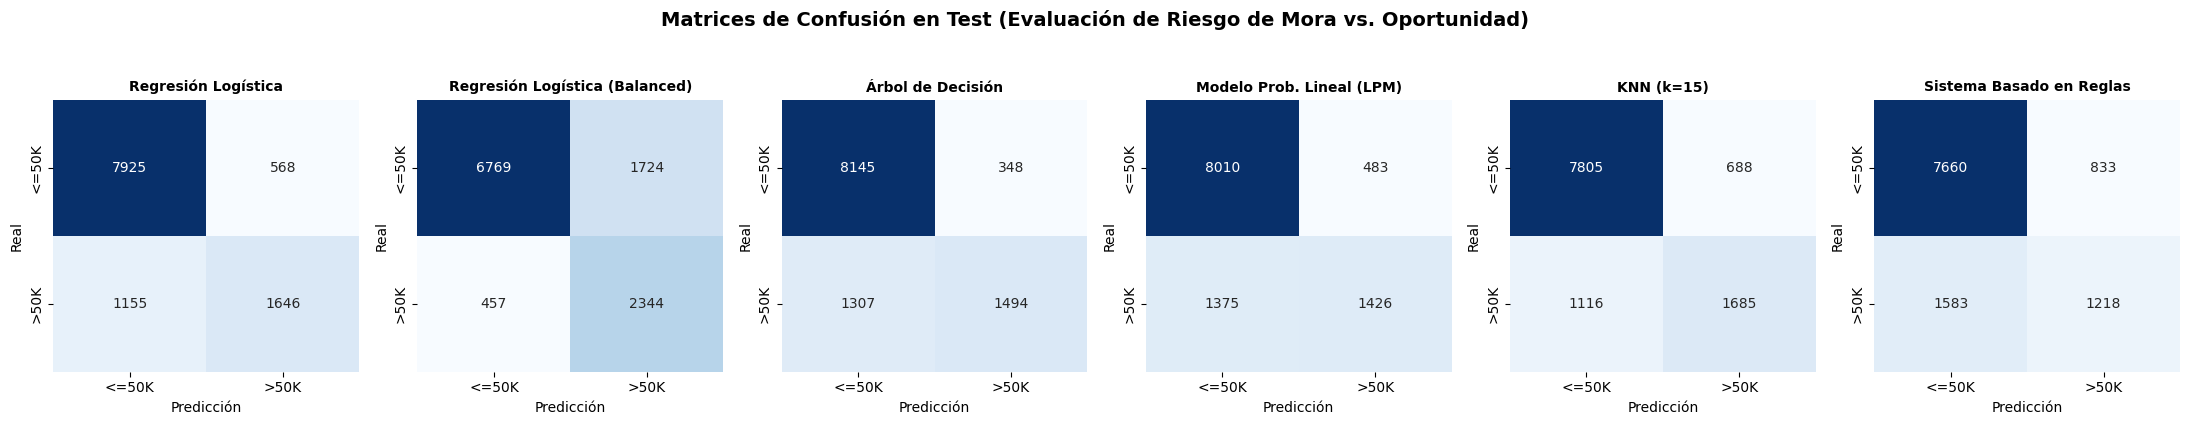

In [ ]:
# ==============================================================================
# 6. MODELADO Y EVALUACIÓN COMPARATIVA
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    balanced_accuracy_score,
    average_precision_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# ------------------------------------------------------------------------------
# 6.1 DEFINICIÓN DEL SISTEMA BASADO EN REGLAS (RULE-BASED HEURISTIC)
# ------------------------------------------------------------------------------
# Supuestos de capital humano:
# 1. Años de educación >= 13 (equivalente a estudios superiores / universitarios)
# 2. Jornada completa de 40 o más horas semanales
# 3. Edad >= 28 años (trayectoria laboral y madurez profesional)
def predict_rule_based(X_df_raw):
  condicion = (
      (X_df_raw['anios_educacion'] >= 13)
      & (X_df_raw['horas_por_semana'] >= 40)
      & (X_df_raw['edad'] >= 28)
  )
  return condicion.astype(int).values


# ------------------------------------------------------------------------------
# 6.2 CONFIGURACIÓN DE MODELOS EMPÍRICOS (DATA-DRIVEN)
# ------------------------------------------------------------------------------
modelos = {
    'Regresión Logística': LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    'Regresión Logística (Balanced)': LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
    'Árbol de Decisión': DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50, random_state=RANDOM_STATE
    ),
    'Modelo Prob. Lineal (LPM)': LinearRegression(),
}

# ==============================================================================
# 6.2.1 BÚSQUEDA DEL MEJOR K PARA KNN (validación cruzada sobre train)
# ==============================================================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

cv_knn = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

valores_k = [3, 5, 7, 9, 11, 15, 21]
resultados_k = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    f1_folds = []
    for train_idx, val_idx in cv_knn.split(X_train, y_train):
        X_tr_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]
        knn.fit(X_tr_fold, y_tr_fold)
        f1_folds.append(f1_score(y_val_fold, knn.predict(X_val_fold)))
    resultados_k.append({'K': k, 'F1 promedio (CV)': np.mean(f1_folds)})

df_k = pd.DataFrame(resultados_k)
print('=== BÚSQUEDA DE K PARA KNN (F1 promedio en 5-Fold CV sobre train) ===')
display(df_k)

mejor_k = df_k.loc[df_k['F1 promedio (CV)'].idxmax(), 'K']
print(f'\nMejor K encontrado: {mejor_k}')

# ==============================================================================
# 6.2.2 AGREGAR KNN AL DICCIONARIO DE MODELOS, CON EL MEJOR K ENCONTRADO
# ==============================================================================
modelos['KNN (k=' + str(mejor_k) + ')'] = KNeighborsClassifier(n_neighbors=mejor_k)

print(f"Modelos actuales en la comparación: {list(modelos.keys())}")
# ------------------------------------------------------------------------------
# 6.3 EVALUACIÓN VIA 5-FOLD CROSS VALIDATION EN TRAIN
# ------------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultados_cv = []

for nombre, mod in modelos.items():
  f1_folds, auc_folds, prec_folds, rec_folds = [], [], [], []

  for train_idx, val_idx in cv.split(X_train, y_train):
    X_tr_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

    mod.fit(X_tr_fold, y_tr_fold)

    if nombre == 'Modelo Prob. Lineal (LPM)':
      preds_prob = np.clip(mod.predict(X_val_fold), 0, 1)
      preds_cls = (preds_prob >= 0.5).astype(int)
    else:
      preds_prob = mod.predict_proba(X_val_fold)[:, 1]
      preds_cls = mod.predict(X_val_fold)

    f1_folds.append(f1_score(y_val_fold, preds_cls))
    auc_folds.append(roc_auc_score(y_val_fold, preds_prob))
    prec_folds.append(precision_score(y_val_fold, preds_cls, zero_division=0))
    rec_folds.append(recall_score(y_val_fold, preds_cls))

  resultados_cv.append({
      'Modelo': nombre,
      'ROC-AUC (CV)': np.mean(auc_folds),
      'F1-Score (CV)': np.mean(f1_folds),
      'Precision (CV)': np.mean(prec_folds),
      'Recall (CV)': np.mean(rec_folds),
  })

df_cv = pd.DataFrame(resultados_cv).set_index('Modelo')
print('=== RESULTADOS CROSS-VALIDATION (5 Folds - Train) ===')
display(df_cv.round(4))

# ------------------------------------------------------------------------------
# 6.4 EVALUACIÓN FINAL EN TEST (COMPARANDO CON EL SISTEMA DE REGLAS)
# ------------------------------------------------------------------------------
metricas_test = []
predicciones_test = {}
probabilidades_test = {}

def calcular_metricas(nombre, y_true, pred, prob):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_true, pred),
        'Balanced Acc': balanced_accuracy_score(y_true, pred),
        'Recall': recall_score(y_true, pred),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'F1-Score': f1_score(y_true, pred),
        'ROC-AUC': roc_auc_score(y_true, prob),
        'PR-AUC': average_precision_score(y_true, prob),
        'RMSE': np.sqrt(mean_squared_error(y_true, prob)),
        'MAE': mean_absolute_error(y_true, prob),
        'R2': r2_score(y_true, prob),
    }

# Modelos Machine Learning
for nombre, mod in modelos.items():
    mod.fit(X_train, y_train)

    if nombre == 'Modelo Prob. Lineal (LPM)':
        prob = np.clip(mod.predict(X_test), 0, 1)
        pred = (prob >= 0.5).astype(int)
    else:
        prob = mod.predict_proba(X_test)[:, 1]
        pred = mod.predict(X_test)

    predicciones_test[nombre] = pred
    probabilidades_test[nombre] = prob
    metricas_test.append(calcular_metricas(nombre, y_test, pred, prob))

# Sistema de reglas (sobre X_test_raw)
pred_reglas = predict_rule_based(X_test_raw)
prob_reglas = pred_reglas.astype(float)

predicciones_test['Sistema Basado en Reglas'] = pred_reglas
probabilidades_test['Sistema Basado en Reglas'] = prob_reglas
metricas_test.append(
    calcular_metricas('Sistema Basado en Reglas', y_test, pred_reglas, prob_reglas)
)

df_test = pd.DataFrame(metricas_test).set_index('Modelo')
print('\n=== COMPARACIÓN FINAL EN TEST (DATA-DRIVEN VS. REGLAS) ===')
display(df_test.round(4))

# Nota: el sistema de reglas emite solo 0 o 1 (sin probabilidades), por lo que
# su ROC-AUC,RMSE, MAE y R² no son directamente comparables con los de los modelos.
# La comparación más justa con las reglas es en Accuracy,Precision, Recall y F1.


# ------------------------------------------------------------------------------
# 6.5 CURVAS ROC COMPARATIVAS
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 7))
for nombre, prob in probabilidades_test.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val = roc_auc_score(y_test, prob)

    # CORRECCIÓN: Esta línea debe estar indentada dentro del bucle for
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc_val:.3f})', linewidth=2)

# Esta línea sí va fuera del bucle (es la diagonal de referencia)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Clasificador Aleatorio')

plt.title(
    'Curvas ROC Comparativas: Modelos Empíricos vs. Sistema Heurístico',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Recall / TPR)', fontsize=11)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 6.6 MATRICES DE CONFUSIÓN Y TRADE-OFF FINANCIERO
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, len(predicciones_test), figsize=(22, 4))

for idx, (nombre, pred) in enumerate(predicciones_test.items()):
  cm = confusion_matrix(y_test, pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      cbar=False,
      ax=axes[idx],
      xticklabels=['<=50K', '>50K'],
      yticklabels=['<=50K', '>50K'],
  )
  axes[idx].set_title(f'{nombre}', fontsize=10, fontweight='bold')
  axes[idx].set_xlabel('Predicción')
  axes[idx].set_ylabel('Real')

plt.suptitle(
    'Matrices de Confusión en Test (Evaluación de Riesgo de Mora vs.'
    ' Oportunidad)',
    fontsize=14,
    fontweight='bold',
    y=1.05,
)
plt.tight_layout()
plt.show()

### 📌 Aclaratoria Metodológica: Uso de métricas de regresión (RMSE, MAE, R²) en clasificación

En este análisis, estas tres métricas no evalúan la predicción final binaria (0 o 1), sino **la calidad de la probabilidad** que cada modelo entrega antes de aplicar el umbral de corte (default 0.5).

- **RMSE** (matemáticamente equivalente al *Brier Score* en este contexto) y **MAE** miden qué tan cerca está esa probabilidad predicha del resultado real (0 o 1).
- **R²** compara el desempeño del modelo contra un *baseline* ingenuo: predecir siempre el promedio general de la clase minoritaria (~24% de casos >50K). Un R² cercano a 0 indica que el modelo aporta poco sobre ese promedio fijo; un R² negativo (como el observado en el Sistema de Reglas) indica que el modelo es *peor* que simplemente predecir la media global.

Estas métricas aportan una perspectiva que Accuracy, Recall o F1-Score no pueden ofrecer por sí solas: distinguen entre un modelo con probabilidades bien calibradas (altamente útil si luego se ajusta el umbral de decisión) y uno que acierta sin gradación real de confianza.

******************************************************************************************************************************************************************


## 6.7 BALANCEO DE CLASES: class_weight='balanced' vs SMOTENC

Esta sección amplía la comparación de balanceo iniciada en 6.2 (donde solo se probó class_weight='balanced' en la Regresión Logística). Se agrega:

1. Una versión de Árbol de Decisión con class_weight='balanced', para tener el mismo tipo de comparación que ya existe en Regresión Logística.
2. SMOTENC (en vez de SMOTE "vainilla") como tercera estrategia de balanceo, aplicado solo sobre X_train/y_train (nunca sobre test, para no filtrar información) -- y usando SMOTENC en lugar de SMOTE porque la mayoría de las predictoras de este dataset son dummies 0/1 (clase_trabajo_*, ocupacion_*, estado_civil_*, etc.). SMOTE "vainilla" interpola TODAS las columnas por igual, así que podría generar un caso sintético con sexo_Male = 0.37, un valor que no existe en la realidad. SMOTENC recibe explícitamente los índices de las columnas categóricas y, para esas columnas, en vez de interpolar toma el valor de un vecino real -- solo interpola las columnas numéricas continuas (edad, anios_educacion, horas_por_semana, ganancia_capital, perdida_capital).
3. Una tabla y un gráfico comparando las 3 estrategias (sin balanceo / class_weight='balanced' / SMOTENC) para Regresión Logística Y Árbol de Decisión -- no solo para Regresión Logística.

In [ ]:
!pip install imbalanced-learn

=== Árbol de Decisión (Balanced) agregado a la comparación ===
Recall clase 1: 0.8590 | F1: 0.6713

APLICANDO SMOTENC SOBRE EL SET DE ENTRENAMIENTO

Distribucion ANTES de SMOTENC (solo train):
ingreso_mayor_50k
0    25480
1     8401
Name: count, dtype: int64

Columnas tratadas como categoricas por SMOTENC: 25 de 30

Distribucion DESPUES de SMOTENC (solo train):
ingreso_mayor_50k
1    25480
0    25480
Name: count, dtype: int64

--- Regresión Logística (SMOTENC) ---
Accuracy    : 0.8062
Precision   : 0.5747
Recall      : 0.8404
F1-Score    : 0.6826
ROC-AUC     : 0.9036

--- Árbol de Decisión (SMOTENC) ---
Accuracy    : 0.7909
Precision   : 0.5504
Recall      : 0.8565
F1-Score    : 0.6701
ROC-AUC     : 0.8928

COMPARACION COMPLETA: Sin balanceo vs class_weight vs SMOTENC


,Recall (Sin balanceo),Recall (class_weight),Recall (SMOTENC),F1 (Sin balanceo),F1 (class_weight),F1 (SMOTENC)
Modelo,,,,,,
Regresión Logística,0.5876,0.8368,0.8404,0.6564,0.6825,0.6826
Árbol de Decisión,0.5334,0.8590,0.8565,0.6435,0.6713,0.6701


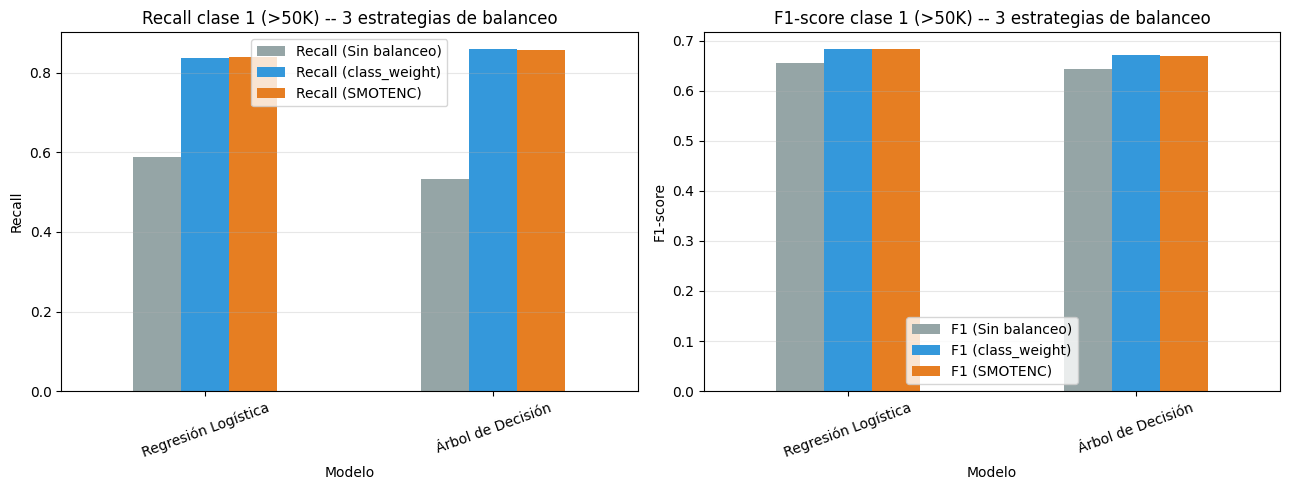

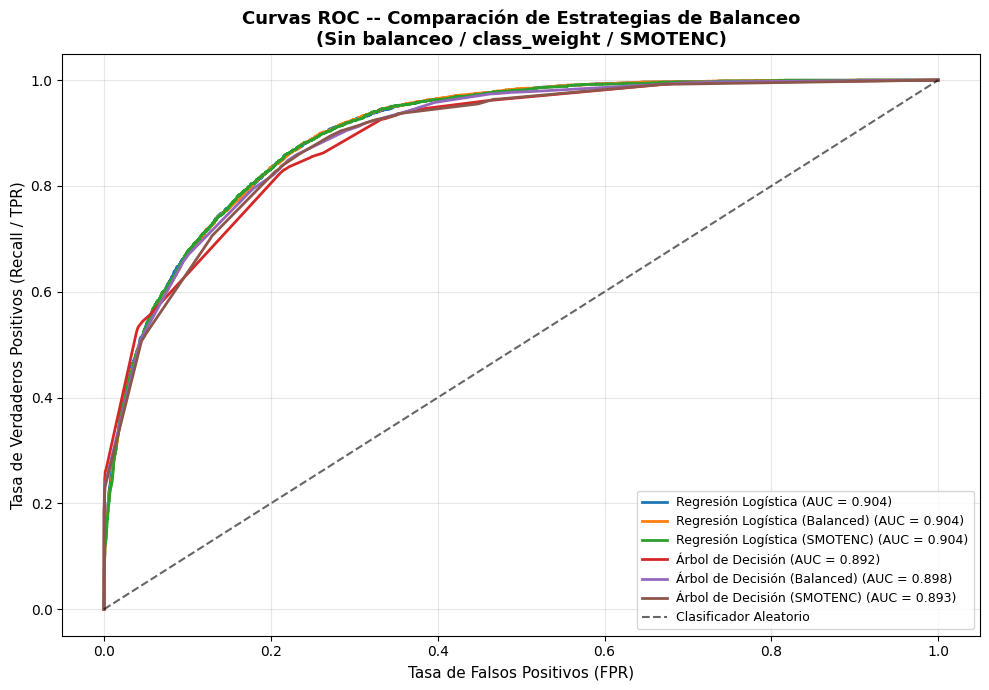

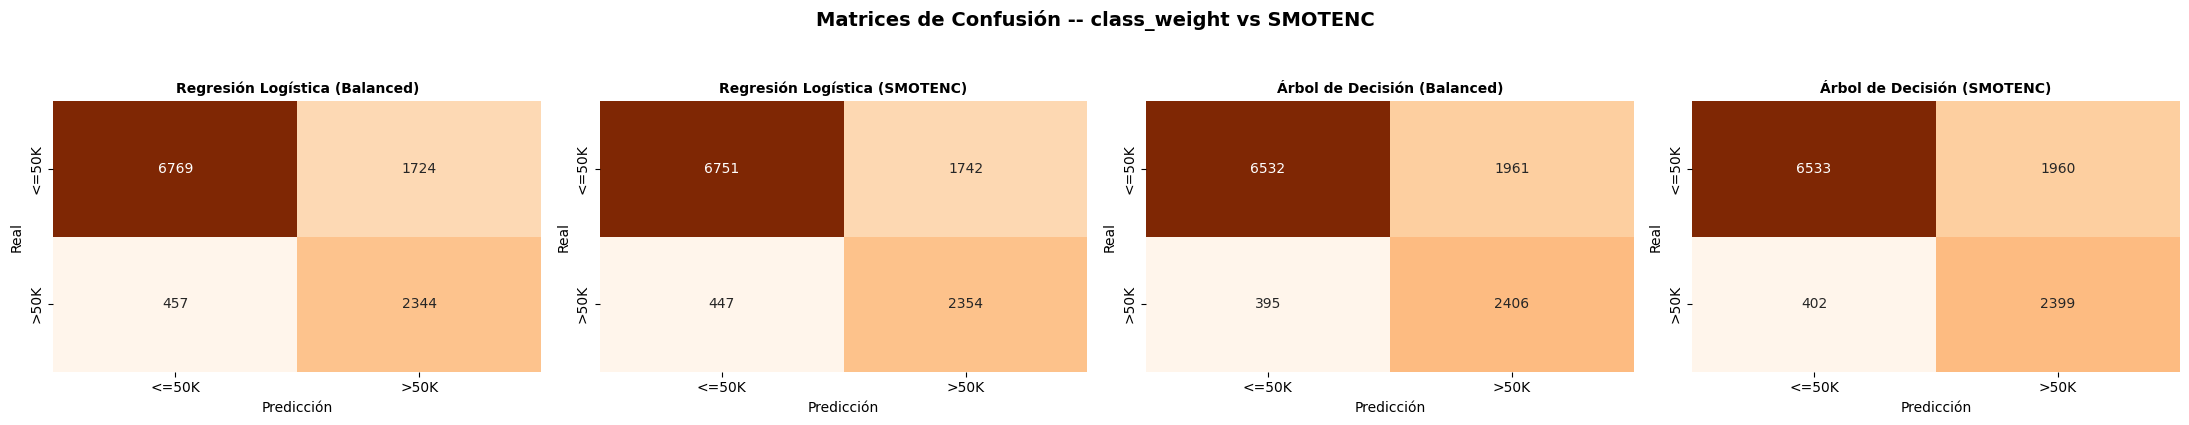

In [ ]:
# ==============================================================================
# 6.7 BALANCEO DE CLASES -- class_weight='balanced' vs SMOTENC
# ==============================================================================
# Requiere: pip install imbalanced-learn

APLICAR_SMOTE = True

if APLICAR_SMOTE:
    from imblearn.over_sampling import SMOTENC

    # --------------------------------------------------------------------
    # 6.7.1 -- Modelo adicional: Árbol de Decisión con class_weight='balanced'
    # (para tener el mismo tipo de comparación que ya existe en Log. Log.)
    # --------------------------------------------------------------------
    modelos['Árbol de Decisión (Balanced)'] = DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50, class_weight='balanced',
        random_state=RANDOM_STATE,
    )
    modelos['Árbol de Decisión (Balanced)'].fit(X_train, y_train)

    pred_arbol_bal = modelos['Árbol de Decisión (Balanced)'].predict(X_test)
    prob_arbol_bal = modelos['Árbol de Decisión (Balanced)'].predict_proba(X_test)[:, 1]

    metricas_test.append({
        'Modelo': 'Árbol de Decisión (Balanced)',
        'Accuracy': accuracy_score(y_test, pred_arbol_bal),
        'Precision': precision_score(y_test, pred_arbol_bal, zero_division=0),
        'Recall': recall_score(y_test, pred_arbol_bal),
        'F1-Score': f1_score(y_test, pred_arbol_bal),
        'ROC-AUC': roc_auc_score(y_test, prob_arbol_bal),
        'RMSE': np.sqrt(mean_squared_error(y_test, prob_arbol_bal)),
        'MAE': mean_absolute_error(y_test, prob_arbol_bal),
        'R2': r2_score(y_test, prob_arbol_bal),
    })

    predicciones_test['Árbol de Decisión (Balanced)'] = pred_arbol_bal
    probabilidades_test['Árbol de Decisión (Balanced)'] = prob_arbol_bal

    print("=== Árbol de Decisión (Balanced) agregado a la comparación ===")
    print(f"Recall clase 1: {recall_score(y_test, pred_arbol_bal):.4f} | "
          f"F1: {f1_score(y_test, pred_arbol_bal):.4f}")

    # --------------------------------------------------------------------
    # 6.7.2 -- SMOTENC sobre X_train / y_train (nunca sobre test)
    # --------------------------------------------------------------------
    print("\n" + "=" * 80)
    print("APLICANDO SMOTENC SOBRE EL SET DE ENTRENAMIENTO")
    print("=" * 80)

    print(f"\nDistribucion ANTES de SMOTENC (solo train):\n{y_train.value_counts()}")

    # Indices de las columnas categoricas (dummies 0/1) dentro de 'predictoras'
    # -- son todas las que NO estan en cols_numericas_reales
    indices_categoricas = [
        predictoras.index(col) for col in predictoras
        if col not in cols_numericas_reales
    ]
    print(f"\nColumnas tratadas como categoricas por SMOTENC: {len(indices_categoricas)} de {len(predictoras)}")

    smote_nc = SMOTENC(categorical_features=indices_categoricas, random_state=RANDOM_STATE)
    X_train_smote, y_train_smote = smote_nc.fit_resample(X_train, y_train)

    print(f"\nDistribucion DESPUES de SMOTENC (solo train):\n{y_train_smote.value_counts()}")

    # --------------------------------------------------------------------
    # 6.7.3 -- Reentrenar Regresión Logística y Árbol de Decisión con SMOTENC
    # (sin class_weight: el balanceo ya lo hizo SMOTENC sobre los datos)
    # --------------------------------------------------------------------
    modelos_smote = {
        'Regresión Logística (SMOTENC)': LogisticRegression(
            max_iter=1000, random_state=RANDOM_STATE
        ),
        'Árbol de Decisión (SMOTENC)': DecisionTreeClassifier(
            max_depth=6, min_samples_leaf=50, random_state=RANDOM_STATE
        ),
    }

    resultados_smote = {}
    for nombre, mod in modelos_smote.items():
        mod.fit(X_train_smote, y_train_smote)
        pred = mod.predict(X_test)
        prob = mod.predict_proba(X_test)[:, 1]

        resultados_smote[nombre] = {
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1-Score': f1_score(y_test, pred),
            'ROC-AUC': roc_auc_score(y_test, prob),
        }

        predicciones_test[nombre] = pred
        probabilidades_test[nombre] = prob

        print(f"\n--- {nombre} ---")
        for k, v in resultados_smote[nombre].items():
            print(f"{k:12s}: {v:.4f}")

    # --------------------------------------------------------------------
    # 6.7.4 -- Tabla comparativa completa: sin balanceo / class_weight / SMOTENC
    # para Regresión Logística Y Árbol de Decisión
    # --------------------------------------------------------------------
    df_test_dict = df_test.to_dict('index')

    filas_comparacion_balanceo = [
        {
            'Modelo': 'Regresión Logística',
            'Recall (Sin balanceo)': df_test_dict['Regresión Logística']['Recall'],
            'Recall (class_weight)': df_test_dict['Regresión Logística (Balanced)']['Recall'],
            'Recall (SMOTENC)': resultados_smote['Regresión Logística (SMOTENC)']['Recall'],
            'F1 (Sin balanceo)': df_test_dict['Regresión Logística']['F1-Score'],
            'F1 (class_weight)': df_test_dict['Regresión Logística (Balanced)']['F1-Score'],
            'F1 (SMOTENC)': resultados_smote['Regresión Logística (SMOTENC)']['F1-Score'],
        },
        {
            'Modelo': 'Árbol de Decisión',
            'Recall (Sin balanceo)': df_test_dict['Árbol de Decisión']['Recall'],
            'Recall (class_weight)': recall_score(y_test, pred_arbol_bal),
            'Recall (SMOTENC)': resultados_smote['Árbol de Decisión (SMOTENC)']['Recall'],
            'F1 (Sin balanceo)': df_test_dict['Árbol de Decisión']['F1-Score'],
            'F1 (class_weight)': f1_score(y_test, pred_arbol_bal),
            'F1 (SMOTENC)': resultados_smote['Árbol de Decisión (SMOTENC)']['F1-Score'],
        },
    ]

    df_comparacion_balanceo = pd.DataFrame(filas_comparacion_balanceo).set_index('Modelo')

    print("\n" + "=" * 80)
    print("COMPARACION COMPLETA: Sin balanceo vs class_weight vs SMOTENC")
    print("=" * 80)
    display(df_comparacion_balanceo.round(4))

    df_comparacion_balanceo.to_csv(
        os.path.join(CARPETA_SALIDAS, "comparacion_balanceo_vs_smote.csv")
    )

    # --------------------------------------------------------------------
    # 6.7.5 -- Gráfico: Recall y F1 por modelo y estrategia de balanceo
    # --------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    df_comparacion_balanceo[
        ['Recall (Sin balanceo)', 'Recall (class_weight)', 'Recall (SMOTENC)']
    ].plot(kind='bar', ax=axes[0], color=['#95a5a6', '#3498db', '#e67e22'])
    axes[0].set_title("Recall clase 1 (>50K) -- 3 estrategias de balanceo")
    axes[0].set_ylabel("Recall")
    axes[0].tick_params(axis='x', rotation=20)
    axes[0].grid(axis='y', alpha=0.3)

    df_comparacion_balanceo[
        ['F1 (Sin balanceo)', 'F1 (class_weight)', 'F1 (SMOTENC)']
    ].plot(kind='bar', ax=axes[1], color=['#95a5a6', '#3498db', '#e67e22'])
    axes[1].set_title("F1-score clase 1 (>50K) -- 3 estrategias de balanceo")
    axes[1].set_ylabel("F1-score")
    axes[1].tick_params(axis='x', rotation=20)
    axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "comparacion_balanceo_vs_smote.png"), dpi=150)
    plt.show()

    # --------------------------------------------------------------------
    # 6.7.6 -- Curva ROC y matrices de confusión incluyendo las versiones SMOTENC
    # (mismo estilo que 6.5 / 6.6, ahora con todos los modelos de esta sección)
    # --------------------------------------------------------------------
    plt.figure(figsize=(10, 7))
    for nombre in ['Regresión Logística', 'Regresión Logística (Balanced)',
                   'Regresión Logística (SMOTENC)', 'Árbol de Decisión',
                   'Árbol de Decisión (Balanced)', 'Árbol de Decisión (SMOTENC)']:
        prob = probabilidades_test[nombre]
        fpr, tpr, _ = roc_curve(y_test, prob)
        auc_val = roc_auc_score(y_test, prob)
        plt.plot(fpr, tpr, label=f'{nombre} (AUC = {auc_val:.3f})', linewidth=2)

    plt.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Clasificador Aleatorio')
    plt.title(
        'Curvas ROC -- Comparación de Estrategias de Balanceo\n'
        '(Sin balanceo / class_weight / SMOTENC)',
        fontsize=13, fontweight='bold',
    )
    plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=11)
    plt.ylabel('Tasa de Verdaderos Positivos (Recall / TPR)', fontsize=11)
    plt.legend(loc='lower right', fontsize=9)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "curva_roc_balanceo.png"), dpi=150)
    plt.show()

    nombres_matrices = ['Regresión Logística (Balanced)', 'Regresión Logística (SMOTENC)',
                        'Árbol de Decisión (Balanced)', 'Árbol de Decisión (SMOTENC)']
    fig, axes = plt.subplots(1, len(nombres_matrices), figsize=(22, 4))
    for idx, nombre in enumerate(nombres_matrices):
        cm = confusion_matrix(y_test, predicciones_test[nombre])
        sns.heatmap(
            cm, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[idx],
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'],
        )
        axes[idx].set_title(f'{nombre}', fontsize=10, fontweight='bold')
        axes[idx].set_xlabel('Predicción')
        axes[idx].set_ylabel('Real')
    plt.suptitle('Matrices de Confusión -- class_weight vs SMOTENC', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SALIDAS, "matrices_confusion_balanceo.png"), dpi=150)
    plt.show()

else:
    print("\n[6.7] SMOTE desactivado (APLICAR_SMOTE = False). Se omite esta sección.")

In [ ]:
df_final = pd.DataFrame([
    calcular_metricas(n, y_test, predicciones_test[n], probabilidades_test[n])
    for n in predicciones_test
]).set_index('Modelo')

print('=== TABLA FINAL: TODOS LOS MODELOS Y ESTRATEGIAS DE BALANCEO (TEST) ===')
display(df_final.sort_values('F1-Score', ascending=False).round(4))

=== TABLA FINAL: TODOS LOS MODELOS Y ESTRATEGIAS DE BALANCEO (TEST) ===


,Accuracy,Balanced Acc,Recall,Specificity,Precision,F1-Score,ROC-AUC,PR-AUC,RMSE,MAE,R2
Modelo,,,,,,,,,,,
Regresión Logística (SMOTENC),0.8062,0.8177,0.8404,0.7949,0.5747,0.6826,0.9036,0.7632,0.3574,0.2451,0.3150
Regresión Logística (Balanced),0.8069,0.8169,0.8368,0.7970,0.5762,0.6825,0.9037,0.7630,0.3583,0.2497,0.3116
Árbol de Decisión (Balanced),0.7914,0.8140,0.8590,0.7691,0.5510,0.6713,0.8983,0.7390,0.3635,0.2527,0.2915
Árbol de Decisión (SMOTENC),0.7909,0.8129,0.8565,0.7692,0.5504,0.6701,0.8928,0.7249,0.3590,0.2455,0.3089
Regresión Logística,0.8474,0.7604,0.5876,0.9331,0.7435,0.6564,0.9041,0.7659,0.3242,0.2100,0.4364
KNN (k=15),0.8403,0.7603,0.6016,0.9190,0.7101,0.6513,0.8887,0.7279,0.3322,0.2084,0.4084
Árbol de Decisión,0.8535,0.7462,0.5334,0.9590,0.8111,0.6435,0.8923,0.7300,0.3240,0.2094,0.4372
Modelo Prob. Lineal (LPM),0.8355,0.7261,0.5091,0.9431,0.7470,0.6055,0.8881,0.7292,0.3428,0.2565,0.3699
Sistema Basado en Reglas,0.7861,0.6684,0.4348,0.9019,0.5939,0.5021,0.6684,0.3984,0.4625,0.2139,-0.1470


Criterio de comparación. La validación cruzada de 5 folds sobre train (6.3) es la referencia para comparar los modelos. El conjunto de test (6.4 y 6.8) se usa como confirmación final, con datos que ningún modelo vio durante el entrenamiento. Los modelos agregados en 6.7 (árbol balanced y SMOTENC) no pasaron por la validación cruzada, por lo que su comparación en la tabla anterior se apoya solo en el test.